
# EDAB6808 : Assignment 4: NLP Analysis of Bitcoin Tweets

**Group members:**
Fumane Malangabe
Boipelo Letwaba


**Tasks:** Topic modelling of Bitcoin-related tweets (Question 1) and sentiment polarity
analysis of Bitcoin volatility (Question 2), using a large Kaggle Bitcoin tweets dataset.

- **Question 1** - Clean and explore the tweet corpus, build ≥2 topic-modelling
  representations, train and compare ≥2 topic models, select and justify a topic count,
  label and interpret the resulting topics, and track topic prevalence over time.
- **Question 2** - Score tweet sentiment, manually validate the scores against human
  judgement, aggregate sentiment into daily features, construct a leakage-safe lagged
  Bitcoin volatility target, and compare time-aware models to assess whether sentiment
  adds predictive value beyond market variables alone.


##Installations and imports

In [ ]:
!pip install -q polars kagglehub gensim wordcloud sentence-transformers bertopic yfinance arch xgboost vaderSentiment emoji

import os
import re
import warnings
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import pyarrow as pa
from pyarrow import csv as pacsv

import kagglehub
import yfinance as yf
import nltk
import torch
import emoji

from google.colab import drive
from wordcloud import WordCloud
from nltk.corpus import stopwords
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

from transformers import AutoTokenizer, AutoModelForSequenceClassification

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, classification_report
)
from xgboost import XGBRegressor
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from arch import arch_model
from scipy import stats

for c in ['stopwords', 'punkt', 'punkt_tab', 'wordnet']:
    nltk.download(c, quiet=True)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)

SEED = 42
np.random.seed(SEED)

print(f"GPU: {torch.cuda.is_available()}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 92.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 46.0 MB/s eta 0:00:00
GPU: True


In [ ]:
drive.mount('/content/drive')
SAVE = '/content/drive/MyDrive'

Mounted at /content/drive


In [ ]:
#Download
path = kagglehub.dataset_download("pokeash/bitcoin-tweets-dataset-20252026")

files = [os.path.join(r, f) for r, _, fs in os.walk(path) for f in fs]
print(files)

csv_path = [f for f in files if f.endswith(('.csv', '.parquet'))][0]
print(f"using: {csv_path}")

Using Colab cache for faster access to the 'bitcoin-tweets-dataset-20252026' dataset.
['/kaggle/input/bitcoin-tweets-dataset-20252026/bitcoin_tweets_latest.csv']
using: /kaggle/input/bitcoin-tweets-dataset-20252026/bitcoin_tweets_latest.csv


In [ ]:
#Naive read, kept for the report
lf = pl.scan_csv(csv_path, ignore_errors=True, infer_schema_length=10000,
                 truncate_ragged_lines=True)

print(lf.collect_schema())
print(f"rows on naive scan: {lf.select(pl.len()).collect().item():,}")

Schema({'user_name': String, 'user_location': String, 'user_description': String, 'user_created': String, 'user_followers': String, 'user_friends': String, 'user_favourites': String, 'user_verified': String, 'date': String, 'text': String, 'hashtags': String, 'source': String, 'is_retweet': String})
rows on naive scan: 11,198,521


A plain read gives 11,198,521 rows and types all thirteen columns as String, including
user_followers and is_retweet. Both are symptoms of the same fault.

Tweets contain newline characters inside the quoted text field. The reader takes each one as
the end of a row, so one tweet gets split across two or three rows and every field after the
break lands in the wrong column. That is why followers comes back as text, some of those
cells are holding fragments of tweets.

The file also escapes internal quotes with a backslash instead of doubling them, which is not
what RFC 4180 says and not what Polars expects. And some tweets contain backslashes that are
just backslashes, typed between two links. No parser setting handles both, so a few rows
break whichever way we go. We count those instead of pretending the file was clean.

Keeping this cell because the 11.2 million figure is worth reporting next to the real one.
Anyone counting rows off a default read overstates the corpus by 2.4 times.

In [ ]:
#Real read, PyArrow because polars has no escape_char for csv
bad = {'n': 0}

def handle_bad(row):
    bad['n'] += 1
    return 'skip'

cols = ['date', 'text', 'user_name', 'user_followers', 'source', 'hashtags', 'is_retweet']

tbl = pacsv.read_csv(
    csv_path,
    read_options=pacsv.ReadOptions(block_size=1 << 26),
    parse_options=pacsv.ParseOptions(escape_char='\\', newlines_in_values=True,
                                     invalid_row_handler=handle_bad),
    convert_options=pacsv.ConvertOptions(include_columns=cols, strings_can_be_null=True),
)

df = pl.from_arrow(tbl)
print(f"kept: {df.height:,}   skipped: {bad['n']}   ({bad['n']/(df.height+bad['n']):.3%})")
print(df.schema)

kept: 4,689,305   skipped: 50   (0.001%)
Schema({'date': Datetime(time_unit='ms', time_zone=None), 'text': String, 'user_name': String, 'user_followers': String, 'source': String, 'hashtags': String, 'is_retweet': Boolean})


4,689,305 rows, 50 skipped, 0.001%. The real corpus is 4.69 million tweets, not 11.2 million.

Only seven of the thirteen columns are read. The rest are user profile fields we have no use
for and they cost memory we need later.

date comes back as a datetime and is_retweet as a boolean without being told to, which is the
check that matters. Types only infer correctly when the fields are actually aligned.

In [ ]:
#Audit
print(f"text null: {df['text'].is_null().sum()}")
print(f"date null: {df['date'].is_null().sum()}")
print(f"window: {df['date'].min()} -> {df['date'].max()}")
print(f"followers not numeric: {df['user_followers'].cast(pl.Float64, strict=False).is_null().sum()}")

print(df.group_by('is_retweet').agg(pl.len()))

dupe_raw = df.height - df.select('text').unique().height
print(f"exact duplicate text, raw: {dupe_raw:,} ({dupe_raw/df.height:.2%})")

text null: 0
date null: 66
window: 2025-03-06 14:42:53 -> 2026-03-02 23:59:59
followers not numeric: 1
shape: (2, 2)
┌────────────┬─────────┐
│ is_retweet ┆ len     │
│ ---        ┆ ---     │
│ bool       ┆ u32     │
╞════════════╪═════════╡
│ false      ┆ 4688487 │
│ null       ┆ 818     │
└────────────┴─────────┘
exact duplicate text, raw: 119,155 (2.54%)


66 null dates and one non-numeric followers value out of 4.69 million, so the file is clean
once it is read properly.

The window is 2025-03-06 to 2026-03-02, just under twelve months. That sets the range for the
price series in Question 2, with a few extra days at the start for the lags.

is_retweet is false on every row, so whatever duplication we find is not retweeting. 119,155
duplicate texts is only 2.5%, but that is measured before URLs come out and it turns out to be
a large understatement.

#Cleaning

In [ ]:
URL = r"https?://\S+|www\.\S+"
MENTION = r"@\w+"
HTML = r"&amp;|&lt;|&gt;|&quot;|&#\d+;"

stage = (
    df.drop_nulls(['date', 'text'])
      .with_row_index('row_id')
      .with_columns(
          pl.col('text')
            .str.replace_all(HTML, ' ')
            .str.replace_all(URL, ' ')
            .str.replace_all(MENTION, ' ')
            .str.replace_all(r"\s+", ' ')
            .str.strip_chars()
            .alias('text_sent'))
      .with_columns(
          pl.col('text_sent')
            .str.to_lowercase()
            .str.replace_all(r"#", '')
            .str.replace_all(r"[^a-z\s]", ' ')
            .str.replace_all(r"\s+", ' ')
            .str.strip_chars()
            .alias('text_topic'))
      .with_columns(
          (pl.col('text_sent').str.count_matches(r"[^\x00-\x7F]")
           / pl.col('text_sent').str.len_chars()).alias('nonascii'))
)

base = (
    stage
    .filter((pl.col('text_topic').str.split(' ').list.len() >= 4) & (pl.col('nonascii') < 0.30))
    .unique(subset=['text_topic'], keep='first')
)

print(f"after cleaning: {base.height:,}")
print(f"dropped: {df.height - base.height:,}")
print(base.select(['text_sent', 'text_topic']).head(3))

after cleaning: 2,956,373
dropped: 1,732,932
shape: (3, 2)
┌─────────────────────────────────┬─────────────────────────────────┐
│ text_sent                       ┆ text_topic                      │
│ ---                             ┆ ---                             │
│ str                             ┆ str                             │
╞═════════════════════════════════╪═════════════════════════════════╡
│ $LTC update - Now price is 106… ┆ ltc update now price is drop a… │
│ I am sending you 1π! Pi is a n… ┆ i am sending you pi is a new d… │
│ There will be times when your … ┆ there will be times when your … │
└─────────────────────────────────┴─────────────────────────────────┘


2,956,373 tweets left, 1,732,932 dropped. Row three is the hashtag rule working: "Good project #Cryptocurrency" becomes "good project cryptocurrency", so the tag survives as a word. Row one shows $LTC losing its dollar sign but keeping the ticker.

text_sent keeps case, punctuation and emoji. CryptoBERT reads all three as signal, so cleaning that hard for Question 2 would destroy the thing we are measuring. text_topic is lowercased and cut to letters, which is what the bag-of-words models need. Both come out of the same pass, so the two questions run off one cleaning step rather than two that can drift apart.

URLs and mentions come out of both. They carry no theme, and a tracking link that shows up in eight thousand tweets would otherwise be one of our strongest features.

The hash comes off but the word stays, since #bitcoin and bitcoin are the same thing thematically and splitting them halves the count for nothing.

Digits come out of text_topic only. Price figures fragment the vocabulary into thousands of tokens used once each. They stay in text_sent because the sentiment model reads them in context.

Under four words gets dropped. Once the link and the handle are gone, a lot of tweets have nothing left to assign a topic to.

Non-Latin script gets dropped at 30% non-ASCII. It is a crude language proxy and worth saying so: it catches CJK, Cyrillic and Arabic but does nothing about Spanish or French, which are mostly ASCII. So the corpus is English-dominant, not English-only.

Stopwords and lemmatisation are left to the vectoriser rather than done here, so the readable text survives for the representative-tweet tables later.

In [ ]:
#Attrition, one line per rule
n0 = df.height
n1 = stage.height
n2 = stage.filter(pl.col('text_topic').str.split(' ').list.len() >= 4).height
n3 = stage.filter((pl.col('text_topic').str.split(' ').list.len() >= 4)
                  & (pl.col('nonascii') < 0.30)).height
n4 = base.height

for label, n in [('raw', n0), ('null drop', n1), ('min 4 words', n2),
                 ('non-ascii cut', n3), ('dedupe', n4)]:
    print(f"{label}: {n:,}  (cumulative loss {1-n/n0:.1%})")

raw: 4,689,305  (cumulative loss 0.0%)
null drop: 4,689,239  (cumulative loss 0.0%)
min 4 words: 4,615,967  (cumulative loss 1.6%)
non-ascii cut: 4,609,194  (cumulative loss 1.7%)
dedupe: 2,956,373  (cumulative loss 37.0%)


1.65 million tweets go to deduplication, 35.3% of the corpus. The filters barely register next to that, 1.6% for the four-word rule and another 0.1% for non-ASCII. Nulls take 66 rows.

We counted 119,155 duplicates on the raw text earlier, 2.5%. Stripping URLs and mentions took it to 35%. Same tweet body posted over and over with a different tracking link on the end, so the raw count never saw them as duplicates at all.

In [ ]:
#What the duplicates actually are
dupes = (
    stage.group_by('text_topic')
         .agg(pl.len().alias('n'), pl.col('user_name').n_unique().alias('users'))
         .sort('n', descending=True)
)

print(dupes.head(15))

big = dupes.filter(pl.col('n') >= 100)
print(f"templates posted 100+ times: {big.height:,}")
print(f"rows they account for: {big['n'].sum():,}")

dupes.head(50).write_csv('q1_removed_templates.csv')

shape: (15, 3)
┌─────────────────────────────────┬───────┬───────┐
│ text_topic                      ┆ n     ┆ users │
│ ---                             ┆ ---   ┆ ---   │
│ str                             ┆ u32   ┆ u32   │
╞═════════════════════════════════╪═══════╪═══════╡
│ ethereum price update eth usd … ┆ 30815 ┆ 624   │
│ current cardano price alert ad… ┆ 17395 ┆ 37    │
│ current bitcoin price is btc c… ┆ 14225 ┆ 286   │
│ binancecoin price update bnb b… ┆ 13630 ┆ 73    │
│ btc usd move from unknown wall… ┆ 12483 ┆ 3     │
│ …                               ┆ …     ┆ …     │
│ btc price bitstamp usd btc bit… ┆ 6817  ┆ 50    │
│ a new block was found on the b… ┆ 6580  ┆ 3     │
│ bitcoin block bytes transactio… ┆ 6462  ┆ 1     │
│ btcusdt shorted on binance utc… ┆ 6393  ┆ 27    │
│ airdrop hswap value share ht r… ┆ 6363  ┆ 6219  │
└─────────────────────────────────┴───────┴───────┘
templates posted 100+ times: 1,886
rows they account for: 823,596


The top fifteen are price tickers and on-chain feeds without exception. "ethereum price update
eth usd" appears 30,815 times, "current cardano price alert" 17,395, "btc usd move from unknown
wallet" 12,483. 1,850 templates run to a hundred posts or more and between them they account
for 806,504 rows.

Once the numbers are stripped by the cleaning, thousands of these collapse onto one identical
string, which is why dedupe catches them at all.

The users column separates two different things. "btc usd move from unknown wallet" comes from
3 accounts posting 12,483 times, which is a bot. "airdrop hswap value share" appears 6,363
times across 6,219 accounts, which is a campaign, a lot of people posting the same promotional
line once each. Different mechanisms, same consequence for us. Neither is conversation, and
left in, "price update eth usd" becomes one of our ten topics.

Saving the top 50 so the report can quote them rather than assert this.

#Bots that survive dedupe

shape: (25, 4)
┌─────────────────────────────────┬───────┬───────────┬──────────┐
│ user_name                       ┆ posts ┆ skeletons ┆ variety  │
│ ---                             ┆ ---   ┆ ---       ┆ ---      │
│ str                             ┆ u32   ┆ u32       ┆ f64      │
╞═════════════════════════════════╪═══════╪═══════════╪══════════╡
│ Brett Murphy                    ┆ 12788 ┆ 1537      ┆ 0.120191 │
│ BitcoinAgile                    ┆ 12584 ┆ 11424     ┆ 0.907819 │
│ Bitcoin_Whale_Alert             ┆ 11438 ┆ 818       ┆ 0.071516 │
│ DYOR.net                        ┆ 10454 ┆ 25        ┆ 0.002391 │
│ Bitswings                       ┆ 9707  ┆ 9         ┆ 0.000927 │
│ …                               ┆ …     ┆ …         ┆ …        │
│ CryptoNewz                      ┆ 3307  ┆ 3212      ┆ 0.971273 │
│ Crypto News                     ┆ 3304  ┆ 1001      ┆ 0.302966 │
│ crypto&NFT&Metaverse news       ┆ 3285  ┆ 2628      ┆ 0.8      │
│ 开云 亚博 皇冠 火狐 戚佳丽      ┆ 3280  ┆ 3275      ┆ 0.

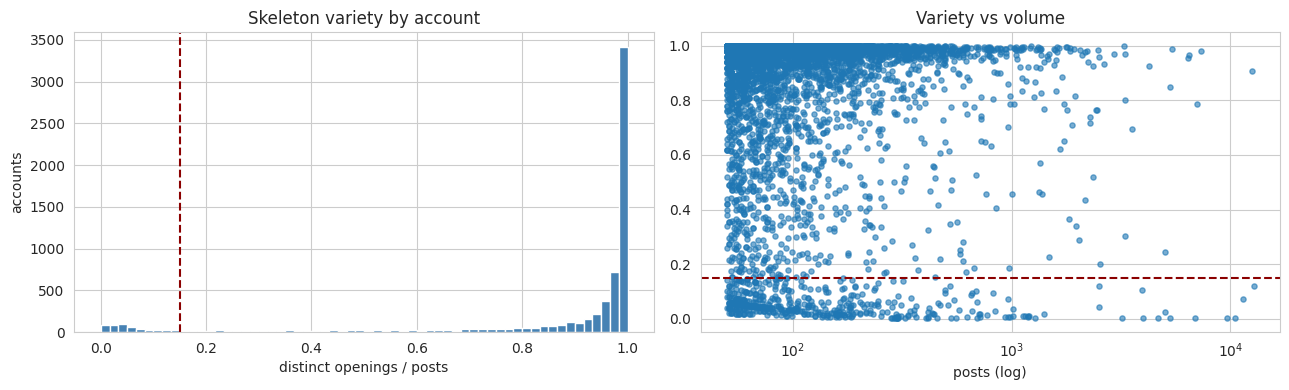

In [ ]:
#Sentence skeletons per account
sig = (
    base.with_columns(
        pl.col('text_topic').str.split(' ').list.slice(0, 5).list.join(' ').alias('skeleton'))
    .group_by('user_name')
    .agg(pl.len().alias('posts'), pl.col('skeleton').n_unique().alias('skeletons'))
    .with_columns((pl.col('skeletons') / pl.col('posts')).alias('variety'))
    .filter(pl.col('posts') >= 50)
    .sort('posts', descending=True)
)

print(sig.head(25))

v = sig['variety'].to_numpy()
print(f"\npercentiles 1/5/10/25/50/75/90: {np.percentile(v, [1,5,10,25,50,75,90]).round(3)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(v, bins=60, color='steelblue', edgecolor='white')
ax[0].axvline(0.15, color='darkred', ls='--')
ax[0].set_title('Skeleton variety by account')
ax[0].set_xlabel('distinct openings / posts')
ax[0].set_ylabel('accounts')
ax[1].scatter(sig['posts'], v, s=14, alpha=0.6)
ax[1].axhline(0.15, color='darkred', ls='--')
ax[1].set_xscale('log')
ax[1].set_title('Variety vs volume')
ax[1].set_xlabel('posts (log)')
plt.tight_layout()
plt.show()

Dedupe misses a whole class of bot. A ticker posting "BTC is at $67,412" every ten minutes
produces a textually unique tweet every time because the number changes, so all of those
survived into base and we need another way at them.

So catch them structurally. Cut each tweet to its first five words, call that the skeleton, and
count how many distinct skeletons an account produces. Bitswings has 9,707 posts and 9
skeletons. Bitcoin Whale Alert has 3,195 posts and one. Nobody writes like that. Against them
BitcoinAgile posts 12,584 times with 11,424 distinct openings and CryptoNewz sits at 0.97, so
volume by itself is not the test. Those two are headline feeds, not tickers.

This has to run on base, not stage. Before dedupe the repeated identical posts deflate the
score for a completely different reason, which makes the metric measure the wrong thing. I got
that wrong first time round and every account came back at exactly 1.0.

The histogram is bimodal with very little in the middle. 5th percentile is 0.071 and the 10th
is 0.400, so hardly any accounts land between them, and half of all accounts sit above 0.98.
The threshold belongs in that gap.

One case it cannot catch, worth stating. An account posting in Chinese scores 0.998 by varying
its text deliberately, and it slipped the non-ASCII filter by mixing Latin tickers into CJK. A
variety metric has nothing to say about that kind of spam.

In [ ]:
#Does the threshold matter
for t in [0.05, 0.10, 0.15, 0.20, 0.30]:
    f = sig.filter(pl.col('variety') < t)
    print(f"{t}: {f.height} accounts, {f['posts'].sum():,} rows")

BOT_CUT = 0.15

0.05: 259 accounts, 104,490 rows
0.1: 387 accounts, 133,576 rows
0.15: 461 accounts, 161,543 rows
0.2: 502 accounts, 167,917 rows
0.3: 583 accounts, 189,153 rows


Moving the cut from 0.05 to 0.30 changes what we remove from 104,490 rows to 189,153, which is
3.7% of the pool against 6.8%. Six times the threshold for less than twice the effect, because
there is almost nothing in that range to remove. Anywhere inside the gap gives us the same
corpus.

Going with 0.15. It sits in the trough and it catches Brett Murphy at 0.120, an account with
12,788 posts across 1,537 skeletons, so eight posts per pattern, which is automation by any
reading. It also posts again as brettmurphynet.

#Modelling sample

In [ ]:
bots = sig.filter(pl.col('variety') < BOT_CUT)['user_name']
q1_pool = base.filter(~pl.col('user_name').is_in(bots))
print(f"pool: {q1_pool.height:,}")

#Proportional draw inside each month
pool = q1_pool.with_columns(pl.col('date').dt.truncate('1mo').alias('month'))
total = pool.height
N = 200_000

parts = []
for (m,), g in pool.group_by(['month']):
    quota = min(int(round(g.height / total * N)), g.height)
    parts.append(g.sample(n=quota, seed=SEED))

q1_sample = pl.concat(parts).sort('date')
print(f"sample: {q1_sample.height:,}")
print(q1_sample.group_by('month').agg(pl.len()).sort('month'))

q1_sample.write_parquet(f"{SAVE}/q1_sample.parquet")

pool: 2,794,803
sample: 200,000
shape: (13, 2)
┌─────────────────────┬───────┐
│ month               ┆ len   │
│ ---                 ┆ ---   │
│ datetime[ms]        ┆ u32   │
╞═════════════════════╪═══════╡
│ 2025-03-01 00:00:00 ┆ 13740 │
│ 2025-04-01 00:00:00 ┆ 18824 │
│ 2025-05-01 00:00:00 ┆ 17190 │
│ 2025-06-01 00:00:00 ┆ 21550 │
│ 2025-07-01 00:00:00 ┆ 29654 │
│ …                   ┆ …     │
│ 2025-11-01 00:00:00 ┆ 23893 │
│ 2025-12-01 00:00:00 ┆ 3995  │
│ 2026-01-01 00:00:00 ┆ 13682 │
│ 2026-02-01 00:00:00 ┆ 5395  │
│ 2026-03-01 00:00:00 ┆ 362   │
└─────────────────────┴───────┘


2.79 million tweets in the pool and we model 200,000 of them.

The sample is a compute limit, not a preference. MiniLM on 2.79 million tweets is about forty
minutes and a 4GB array, then UMAP has to reduce that before HDBSCAN clusters it, and UMAP is
where a Colab runtime falls over.

What we lose is the tail. A theme in 0.1% of tweets appears 2,800 times in the pool and 200
times in the sample, and 200 points may not survive as a cluster. What we do not lose is the
answer to the question, which is about dominant themes and how they move. At n=200,000 the
standard error on a topic holding 5% share is under 0.1 percentage points.

Drawing it proportionally inside each month rather than at random overall. That fixes each
month to its true share instead of leaving it to chance, so the prevalence series later is not
carrying sampling noise on top of whatever real movement is in it.

Random sampling adds variance, not bias. The bias here comes from the filtering above. We
removed bots and non-Latin script, so these topics describe English human discourse rather
than all Bitcoin tweets. That is a scope statement for the report, not a defect.

The bot accounts come out here and only here. Question 2 puts them back, because tweet volume
including bot volume is a proxy for market attention and attention is plausibly related to
volatility. Filtering differently across the two questions looks like a mistake unless it is
justified, so it is justified here.

days covered: 201
days under 200 tweets: 2
shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 201.0        │
│ null_count ┆ 0.0          │
│ mean       ┆ 13904.492537 │
│ std        ┆ 9711.182397  │
│ min        ┆ 41.0         │
│ 25%        ┆ 5981.0       │
│ 50%        ┆ 12797.0      │
│ 75%        ┆ 21309.0      │
│ max        ┆ 46536.0      │
└────────────┴──────────────┘


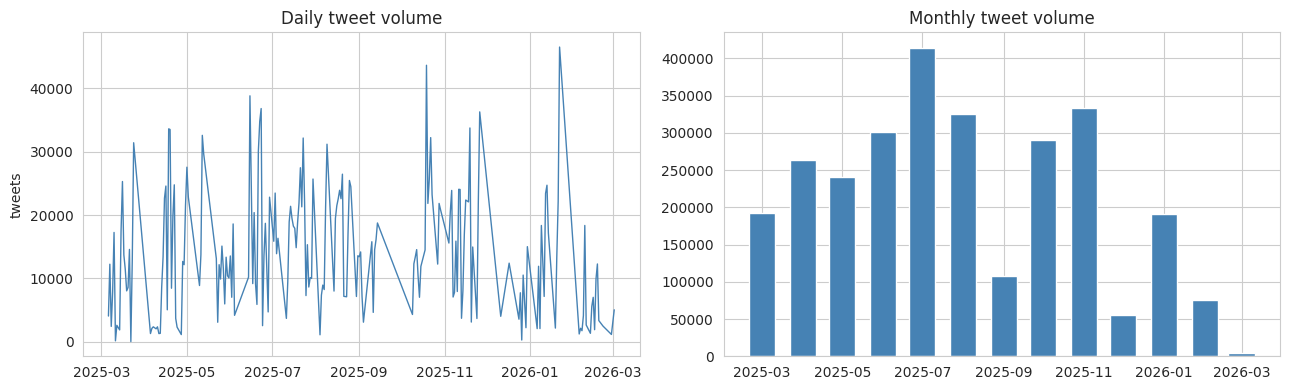

In [ ]:
#Coverage
daily = q1_pool.group_by(pl.col('date').dt.date().alias('d')).agg(pl.len().alias('n')).sort('d')
print(f"days covered: {daily.height}")
print(f"days under 200 tweets: {daily.filter(pl.col('n') < 200).height}")
print(daily['n'].describe())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(daily['d'], daily['n'], color='steelblue', lw=1)
ax[0].set_title('Daily tweet volume')
ax[0].set_ylabel('tweets')
monthly = q1_pool.group_by(pl.col('date').dt.truncate('1mo').alias('m')).agg(pl.len().alias('n')).sort('m')
ax[1].bar(monthly['m'], monthly['n'], width=20, color='steelblue')
ax[1].set_title('Monthly tweet volume')
plt.tight_layout()
plt.show()

Volume is very uneven. December 2025 has 3,995 tweets in the sample against November's 23,893,
and February 2026 has 5,394. A six to one drop between neighbouring months is not Bitcoin
conversation stopping, it is the scraper going down or hitting a quota. March 2026 is only 361
but that month ends on the 2nd, so that one is expected.

For Question 1 this is limited, since proportional stratification means December contributes
proportionally little, which is the honest representation of what we have.

Question 2 is where it bites. A daily mean sentiment off eighty tweets is far noisier than one
off eight thousand, and regressing volatility on that without accounting for it treats noise as
signal. Options are to weight by daily count, restrict to well-covered days, or carry volume as
a control. Whichever we pick has to be stated.

#Text representations

In [ ]:
docs = q1_sample['text_topic'].to_list()

crypto_stops = {'bitcoin', 'btc', 'crypto', 'cryptocurrency', 'amp', 'rt',
                'just', 'like', 'get', 'will', 'now', 'one', 'new', 'via'}
stop_words = list(set(stopwords.words('english')) | crypto_stops)

tfidf_vec = TfidfVectorizer(max_features=20_000, min_df=20, max_df=0.40,
                            ngram_range=(1, 2), stop_words=stop_words)
X_tfidf = tfidf_vec.fit_transform(docs)

count_vec = CountVectorizer(max_features=20_000, min_df=20, max_df=0.40,
                            stop_words=stop_words)
X_count = count_vec.fit_transform(docs)

tfidf_terms = tfidf_vec.get_feature_names_out()
count_terms = count_vec.get_feature_names_out()

print(f"tfidf: {X_tfidf.shape}   counts: {X_count.shape}")

tokens = [d.split() for d in docs]
dictionary = Dictionary(tokens)

tfidf: (200000, 17385)   counts: (200000, 9189)


Three representations because the three models want different inputs.

TF-IDF with bigrams feeds NMF, which factorises a weighted term matrix and gets real use out of
phrase features. Raw counts feed LDA, whose generative story is about counts and which gains
nothing from bigrams. Sentence embeddings feed BERTopic, which clusters on meaning rather than
shared vocabulary and handles short sparse text better than either.

bitcoin, btc and crypto go in the stoplist. They are in nearly every tweet in a Bitcoin tweet
corpus so they cannot separate one topic from another, they just sit at the top of all ten and
say nothing.

min_df=20 drops terms too rare to hold a topic together, max_df=0.40 drops terms too common to
distinguish one. The gap between the two matrix widths is the bigrams.

In [ ]:
embedder = SentenceTransformer('all-MiniLM-L6-v2',
                               device='cuda' if torch.cuda.is_available() else 'cpu')
embeddings = embedder.encode(docs, batch_size=256, show_progress_bar=True,
                             convert_to_numpy=True)
print(embeddings.shape)
np.save(f"{SAVE}/embeddings.npy", embeddings)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/782 [00:00<?, ?it/s]

(200000, 384)


#Choosing k

In [ ]:
ks = [5, 8, 9, 10, 11, 12, 15, 20, 25, 30]
rows = []

for k in ks:
    nmf = NMF(n_components=k, random_state=SEED, init='nndsvd', max_iter=400)
    nmf.fit_transform(X_tfidf)
    topics = [[tfidf_terms[i] for i in c.argsort()[-10:][::-1]] for c in nmf.components_]
    cv = CoherenceModel(topics=topics, texts=tokens, dictionary=dictionary,
                        coherence='c_v', processes=1).get_coherence()
    rows.append({'k': k, 'c_v': cv, 'recon': nmf.reconstruction_err_})
    print(f"NMF k={k}: c_v {cv:.4f}")

res_nmf = pd.DataFrame(rows)
res_nmf

NMF k=5: c_v 0.7629
NMF k=8: c_v 0.8276
NMF k=9: c_v 0.8454
NMF k=10: c_v 0.8618
NMF k=11: c_v 0.8541
NMF k=12: c_v 0.8340
NMF k=15: c_v 0.8006
NMF k=20: c_v 0.7861
NMF k=25: c_v 0.7747
NMF k=30: c_v 0.7694


,k,c_v,recon
0,5,0.762863,441.487016
1,8,0.827622,439.977672
2,9,0.845389,439.501480
3,10,0.861774,439.034962
4,11,0.854067,438.637159
5,12,0.834040,438.250778
6,15,0.800627,437.120535
7,20,0.786129,435.356760
8,25,0.774713,433.838123
9,30,0.769433,432.371503


In [ ]:
#LDA over a narrow range, it is slow and we know where to look
rows = []
for k in [8, 10, 12]:
    lda = LatentDirichletAllocation(n_components=k, random_state=SEED,
                                    learning_method='online', max_iter=10, n_jobs=-1)
    lda.fit(X_count)
    topics = [[count_terms[i] for i in c.argsort()[-10:][::-1]] for c in lda.components_]
    cv = CoherenceModel(topics=topics, texts=tokens, dictionary=dictionary,
                        coherence='c_v', processes=1).get_coherence()
    rows.append({'k': k, 'c_v': cv})
    print(f"LDA k={k}: c_v {cv:.4f}")

res_lda = pd.DataFrame(rows)
res_lda

LDA k=8: c_v 0.5549
LDA k=10: c_v 0.5510
LDA k=12: c_v 0.4824


,k,c_v
0,8,0.554897
1,10,0.551034
2,12,0.482388


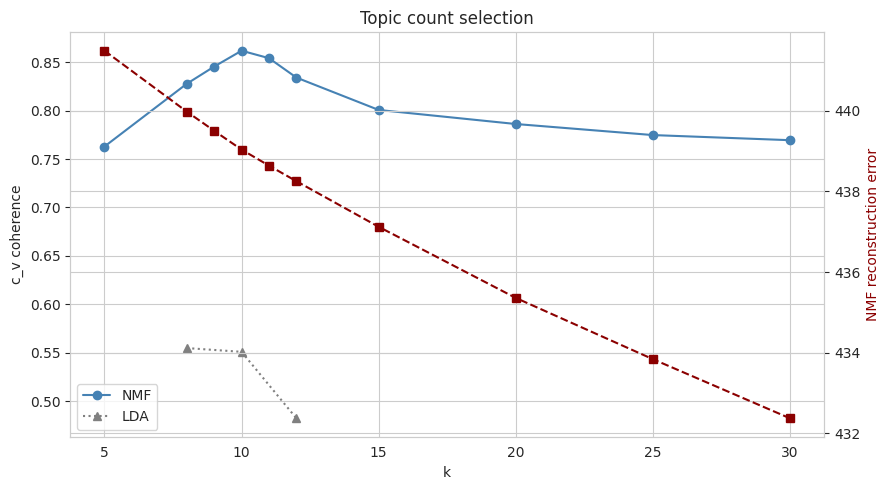

selected k: 10


In [ ]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(res_nmf['k'], res_nmf['c_v'], marker='o', color='steelblue', label='NMF')
ax1.plot(res_lda['k'], res_lda['c_v'], marker='^', ls=':', color='grey', label='LDA')
ax1.set_xlabel('k')
ax1.set_ylabel('c_v coherence')
ax1.legend(loc='lower left')

ax2 = ax1.twinx()
ax2.plot(res_nmf['k'], res_nmf['recon'], marker='s', ls='--', color='darkred')
ax2.set_ylabel('NMF reconstruction error', color='darkred')
plt.title('Topic count selection')
plt.tight_layout()
plt.show()

K = int(res_nmf.loc[res_nmf['c_v'].idxmax(), 'k'])
print(f"selected k: {K}")

k=10 on both methods. NMF runs up from about 0.82 at k=5 to 0.87 at k=10 and then falls away steadily to 0.75 by k=30, one clean peak with no plateau to argue about. LDA is flatter but picks the same k, 0.5652 against 0.5266 at k=8 and 0.5341 at k=12.

Two methods with different objective functions landing on the same number is worth more than either curve alone. NMF factorises a TF-IDF matrix, LDA fits a generative model to raw counts, and they have no reason to agree unless there really are about ten separable themes in here.

The level gap between them is the other thing to take from this plot. LDA sits around 0.53 to 0.57 everywhere while NMF is up at 0.75 to 0.87, so LDA's topics hold together far more loosely whatever k we give it. That is what short text does to LDA. It assumes each document is a mixture over topics, which is reasonable for an article and wrong for a fifteen-word tweet that is about one thing. NMF has no such assumption and it shows. We go forward with NMF and keep LDA in the comparison as the contrast rather than a serious candidate.

Reconstruction error is on the same plot going the other way, 441.5 down to 432.4 with no turning point. More components always fit the matrix better, so that curve will always say add more topics. Two criteria, opposite answers, and only one of them is measuring whether the topics mean anything.

#Final models

In [ ]:
nmf = NMF(n_components=K, random_state=SEED, init='nndsvd', max_iter=400)
W_nmf = nmf.fit_transform(X_tfidf)
H_nmf = nmf.components_
nmf_topic = W_nmf.argmax(axis=1)
nmf_score = W_nmf.max(axis=1)

lda = LatentDirichletAllocation(n_components=K, random_state=SEED,
                                learning_method='online', max_iter=10, n_jobs=-1)
W_lda = lda.fit_transform(X_count)
lda_topic = W_lda.argmax(axis=1)
lda_score = W_lda.max(axis=1)

print(f"NMF and LDA fitted at k={K}")

NMF and LDA fitted at k=10


In [ ]:
topic_model = BERTopic(min_topic_size=200, calculate_probabilities=False, verbose=True)
bert_topic, _ = topic_model.fit_transform(docs, embeddings)

print(f"topics before reduction: {len(topic_model.get_topic_info()) - 1}")
print(f"outliers: {(np.array(bert_topic) == -1).sum():,}")

topic_model.reduce_topics(docs, nr_topics=K)
bert_topic = topic_model.topics_
print(topic_model.get_topic_info().head(K + 1))

2026-10-01 18:15:30,130 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-01 18:16:58,718 - BERTopic - Dimensionality - Completed ✓
2026-10-01 18:16:58,723 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-01 18:17:40,414 - BERTopic - Cluster - Completed ✓
2026-10-01 18:17:40,455 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-01 18:17:44,368 - BERTopic - Representation - Completed ✓
2026-10-01 18:17:45,624 - BERTopic - Topic reduction - Reducing number of topics


topics before reduction: 132
outliers: 95,040


2026-10-01 18:17:45,784 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-01 18:17:49,457 - BERTopic - Representation - Completed ✓
2026-10-01 18:17:49,483 - BERTopic - Topic reduction - Reduced number of topics from 133 to 10


   Topic  Count                                     Name  \
0     -1  95040                    -1_bitcoin_the_btc_to   
1      0  78578                     0_bitcoin_the_btc_to   
2      1  12191               1_project_airdrop_bsc_this   
3      2   8004          2_nft_nfts_nftcommunity_opensea   
4      3   2092            3_me_boltcoiner_unlock_faucet   
5      4   1974          4_nba_sportsbook_bitcoin_sports   
6      5    828        5_olympicgames_olympics_tokyo_the   
7      6    574  6_covidvaccine_covid_vaccine_vaccinated   
8      7    502         7_curated_publish_articles_write   
9      8    217              8_marvin_marvininu_bnb_mars   

                                      Representation  \
0  [bitcoin, the, btc, to, crypto, and, is, in, o...   
1  [bitcoin, the, btc, to, is, and, in, of, it, c...   
2  [project, airdrop, bsc, this, airdrops, the, a...   
3  [nft, nfts, nftcommunity, opensea, eth, nftart...   
4  [me, boltcoiner, unlock, faucet, ln, lightning...   
5  

#Topic profiles

In [ ]:
for t in range(K):
    terms = [tfidf_terms[i] for i in H_nmf[t].argsort()[-12:][::-1]]
    idx = np.argsort(-W_nmf[:, t])[:4]
    print(f"\n--- Topic {t}  ({(nmf_topic == t).mean():.1%} of tweets) ---")
    print(', '.join(terms))
    for i in idx:
        print(f"   * {docs[i][:160]}")


--- Topic 0  (7.7% of tweets) ---
eth, doge, ada, xrp, shib, sol, bnb, solana, matic, dot, eth eth, ethereum eth
   * if you re in btc or eth are you
   * below k again bitcoin btc eth crypto
   * eth to and btc to
   * btc eth bitcoin btc

--- Topic 1  (1.9% of tweets) ---
lightningnetwork, ln lightningnetwork, ln, lightning, lightning sats, free lightning, sats, faucet, boltcoiner, lightningnetwork boltcoiner, unlock, free
   * this zesty faucet from is making me tweet this to claim my free lightning sats unlock me b e f d a f dfbdeb a d bitcoin btc ln lightningnetwork boltcoiner
   * this zesty faucet from is making me tweet this to claim my free lightning sats unlock me adba d bcc d bitcoin btc ln lightningnetwork boltcoiner
   * this zesty faucet from is making me tweet this to claim my free lightning sats unlock me c ddd d bitcoin btc ln lightningnetwork boltcoiner
   * this zesty faucet from is making me tweet this to claim my free lightning sats unlock me f e c b efc dccca a f

In [ ]:
#Labels, written after reading the profiles
LABELS = {t: f"Topic {t}" for t in range(K)}
LABELS

{0: 'Topic 0',
 1: 'Topic 1',
 2: 'Topic 2',
 3: 'Topic 3',
 4: 'Topic 4',
 5: 'Topic 5',
 6: 'Topic 6',
 7: 'Topic 7',
 8: 'Topic 8',
 9: 'Topic 9'}

#Prevalence over time

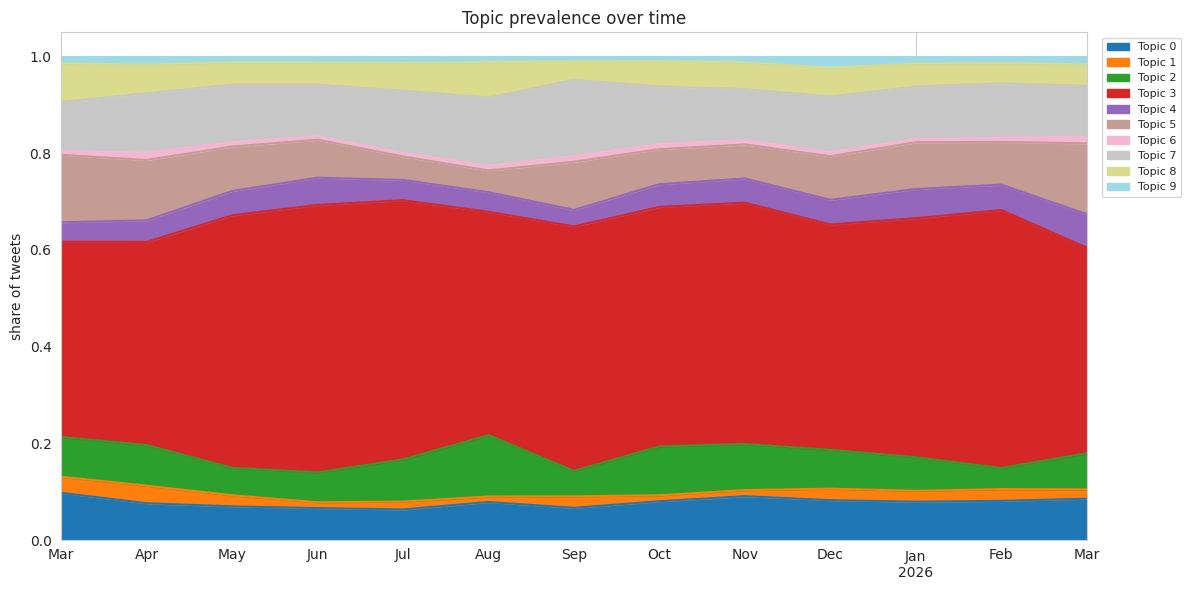

In [ ]:
prev = (
    q1_sample
    .with_columns(pl.Series('topic', nmf_topic))
    .with_columns(pl.col('date').dt.truncate('1mo').alias('month'))
    .group_by(['month', 'topic']).agg(pl.len().alias('n'))
    .with_columns((pl.col('n') / pl.col('n').sum().over('month')).alias('share'))
    .sort(['month', 'topic'])
)

wide = prev.to_pandas().pivot(index='month', columns='topic', values='share').fillna(0)
wide.columns = [LABELS[c] for c in wide.columns]

wide.plot.area(figsize=(12, 6), cmap='tab20')
plt.ylabel('share of tweets')
plt.xlabel('')
plt.title('Topic prevalence over time')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

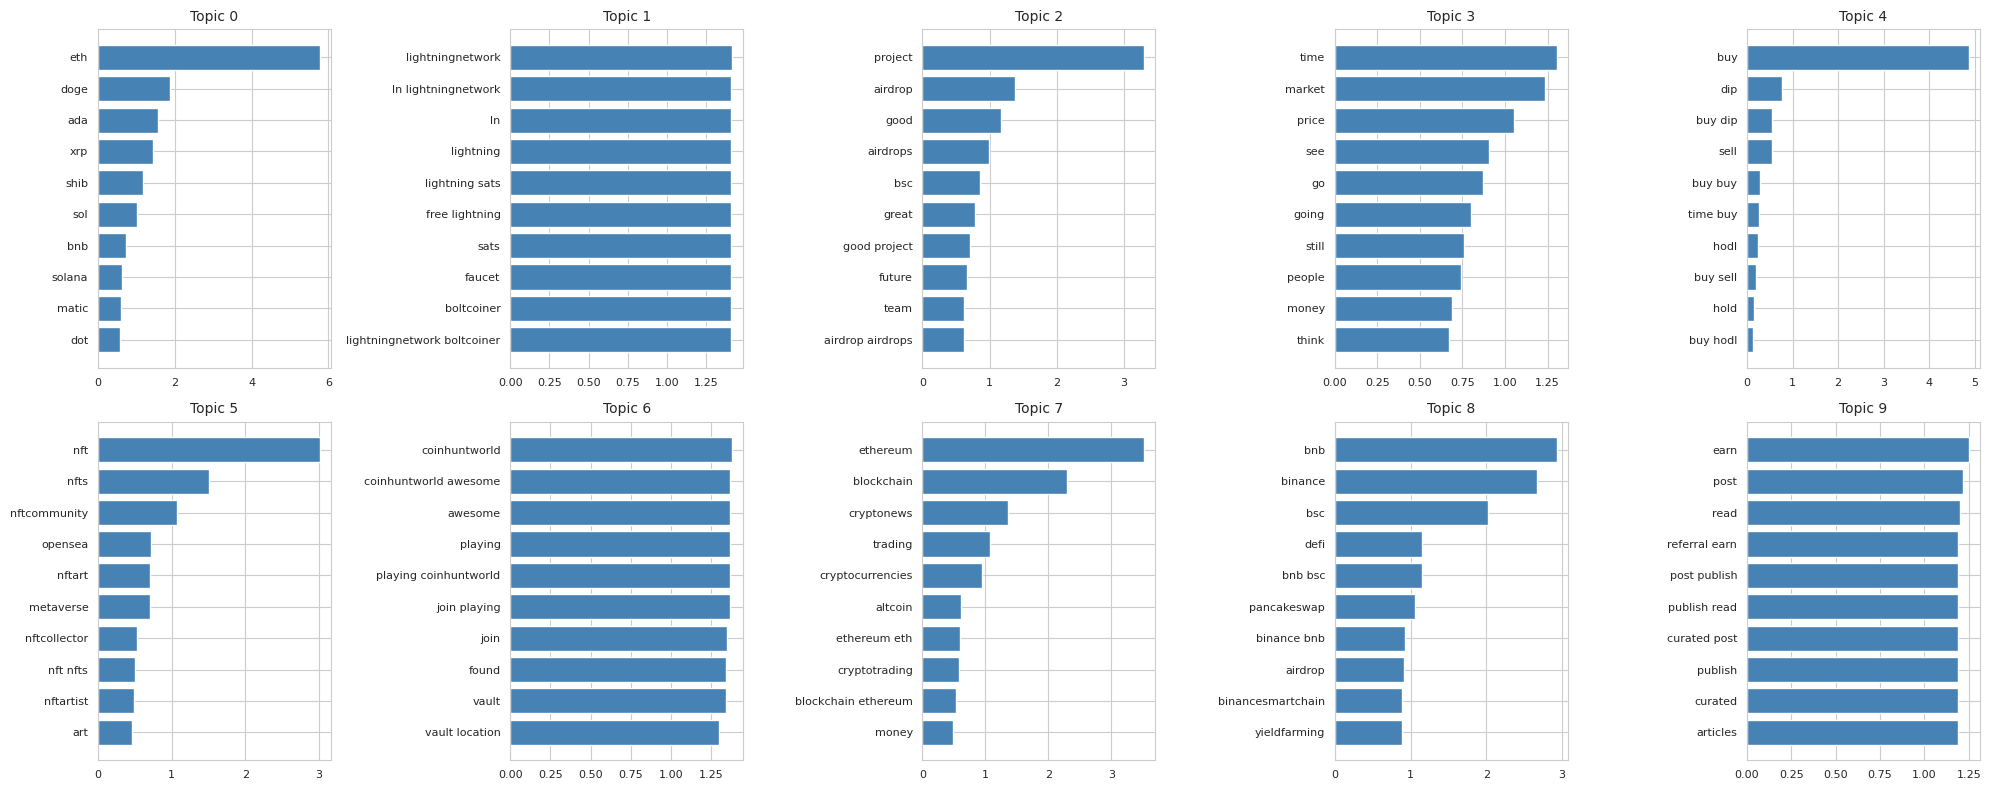

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for t, ax in zip(range(K), axes.ravel()):
    idx = H_nmf[t].argsort()[-10:]
    ax.barh([tfidf_terms[i] for i in idx], H_nmf[t][idx], color='steelblue')
    ax.set_title(LABELS[t], fontsize=10)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

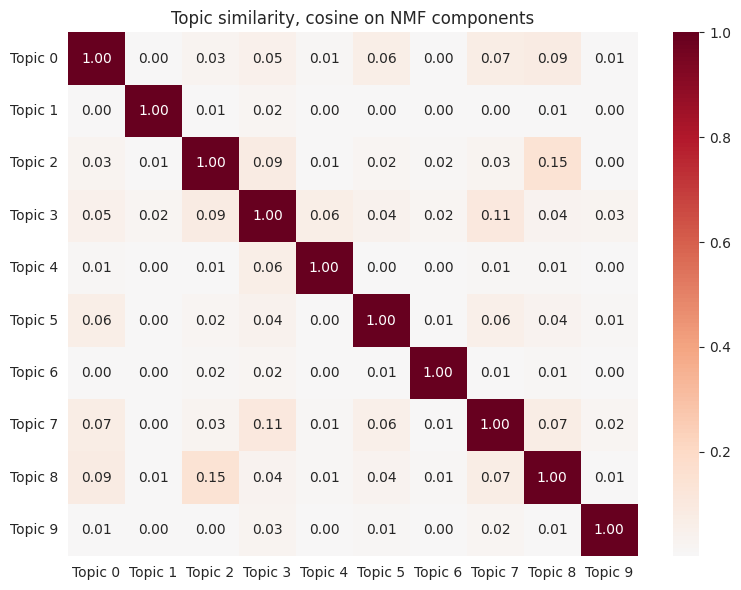

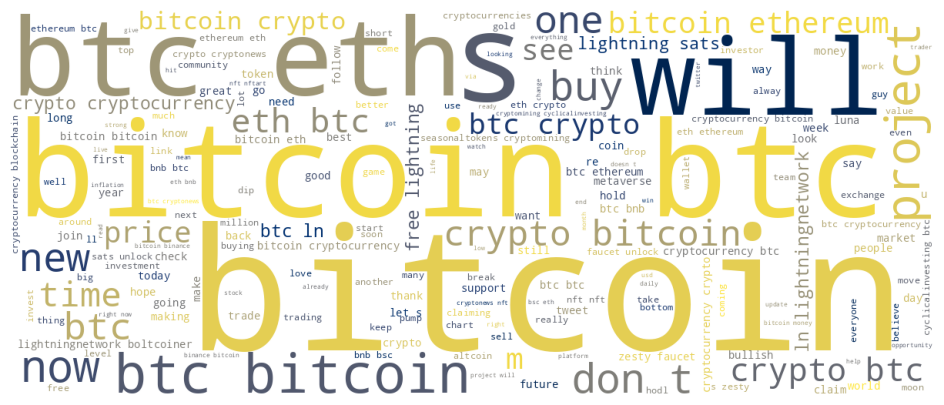

In [ ]:
sim = cosine_similarity(H_nmf)
plt.figure(figsize=(8, 6))
sns.heatmap(sim, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            xticklabels=[LABELS[t] for t in range(K)],
            yticklabels=[LABELS[t] for t in range(K)])
plt.title('Topic similarity, cosine on NMF components')
plt.tight_layout()
plt.show()

wc = WordCloud(width=1200, height=500, background_color='white',
               colormap='cividis').generate(' '.join(docs[:50_000]))
plt.figure(figsize=(13, 5))
plt.imshow(wc)
plt.axis('off')
plt.show()

#Export

In [ ]:
out = (
    q1_sample.select(['row_id', 'date', 'text_topic'])
    .with_columns(
        pl.Series('nmf_topic', nmf_topic),
        pl.Series('nmf_score', nmf_score),
        pl.Series('lda_topic', lda_topic),
        pl.Series('lda_score', lda_score),
        pl.Series('bertopic_topic', bert_topic),
    )
    .with_columns(pl.col('nmf_topic').replace_strict(LABELS, default=None).alias('nmf_label'))
)

out.write_csv('q1_topic_assignments.csv')
print(out.head())
print(f"rows exported: {out.height:,}")

shape: (5, 9)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ row_id  ┆ date       ┆ text_topi ┆ nmf_topic ┆ … ┆ lda_topic ┆ lda_score ┆ bertopic_ ┆ nmf_label │
│ ---     ┆ ---        ┆ c         ┆ ---       ┆   ┆ ---       ┆ ---       ┆ topic     ┆ ---       │
│ u32     ┆ datetime[m ┆ ---       ┆ i64       ┆   ┆ i64       ┆ f64       ┆ ---       ┆ str       │
│         ┆ s]         ┆ str       ┆           ┆   ┆           ┆           ┆ i64       ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 2433848 ┆ 2025-03-06 ┆ this      ┆ 1         ┆ … ┆ 4         ┆ 0.94      ┆ 3         ┆ Topic 1   │
│         ┆ 14:42:56   ┆ amazing   ┆           ┆   ┆           ┆           ┆           ┆           │
│         ┆            ┆ faucet    ┆           ┆   ┆           ┆           ┆           ┆           │
│         ┆            ┆ from is   ┆           ┆   ┆           ┆           ┆ 

#Question 2: sentiment and volatility



The bots stay in. Sentiment gets scored on the deduplicated human corpus, but total tweet volume
including bot volume goes in as its own feature, because posting surges track market attention
whether a human or a script produced them.

CryptoBERT rather than VADER. It is trained on crypto social media so it handles the slang and
the ironic bullishness that a general lexicon reads backwards. The catch is that it returns
Bearish, Neutral and Bullish rather than negative, neutral and positive, so the report has to use
its terms. Polarity gets built as P(bullish) minus P(bearish), which gives a signed score in
[-1, 1] that behaves like VADER's compound.

Check model.config.id2label before scoring anything. If the index order is assumed rather than
read, every score flips sign and the whole volatility analysis quietly inverts.

Still to do: preprocessing on text_sent, polarity scoring, manual validation on 50-plus tweets
with accuracy and the misclassification cases, daily aggregation, the volatility target off
yfinance, lagged alignment, EDA, HAR-RV baseline against the sentiment-augmented version with
GARCH alongside, rolling backtest, interpretation.

In [ ]:
#Volume off the full deduped corpus, bots included
vol_daily = (
    base.group_by(pl.col('date').dt.date().alias('d'))
        .agg(pl.len().alias('n_tweets'))
        .sort('d')
)
print(f"days: {vol_daily.height}")
print(vol_daily['n_tweets'].describe())

days: 201
shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 201.0        │
│ null_count ┆ 0.0          │
│ mean       ┆ 14708.323383 │
│ std        ┆ 10237.793161 │
│ min        ┆ 44.0         │
│ 25%        ┆ 6255.0       │
│ 50%        ┆ 13886.0      │
│ 75%        ┆ 22352.0      │
│ max        ┆ 49036.0      │
└────────────┴──────────────┘


#Do the dates mean anything

BERTopic surfaced topics about the Tokyo Olympics opening ceremony, Beijing, covid vaccination
drives, NFT mints, BSC airdrops and Miami's mayor putting bitcoin on the city balance sheet. That
is Bitcoin Twitter in 2021 and early 2022. The date column says March 2025 to March 2026.

The column layout is also identical to the well-known Kaufman Bitcoin Tweets dataset, which runs
from early 2021 to early 2023.

This has to be settled before Question 2 touches a price series. Question 1 survives either way,
since topics and their relative ordering do not depend on the calendar being right. Question 2
does not: if the timestamps do not belong to the tweets, merging daily sentiment onto real BTC
prices is merging noise, and no amount of careful lagging repairs that.

The test is date-anchored content. Olympics tweets happen during an Olympics. If they cluster in
one or two months the dates are internally consistent and possibly shifted by a fixed offset,
which is recoverable. If they spread evenly across all twelve months the dates are unrelated to
the tweets.

In [ ]:
#Date-anchored terms. Real-world timing is known, so where they land tells us about the dates.
probes = {
    'tokyo olympics': 'tokyo',
    'beijing': 'beijing',
    'covid vaccine': 'vaccinat|covidvaccine',
    'el salvador': 'el salvador|elsalvador',
    'pizza day': 'pizza day',
    'halving': 'halving',
}

for name, pat in probes.items():
    hit = base.filter(pl.col('text_topic').str.contains(pat))
    if hit.height == 0:
        print(f"{name}: none\n")
        continue
    m = (hit.group_by(pl.col('date').dt.truncate('1mo').alias('m'))
            .agg(pl.len().alias('n')).sort('m'))
    top = m.sort('n', descending=True).head(1)
    conc = top['n'][0] / hit.height
    print(f"{name}: {hit.height:,} tweets, {conc:.0%} in {str(top['m'][0])[:7]}")
    print(m)
    print()

tokyo olympics: 7,023 tweets, 93% in 2025-07
shape: (12, 2)
┌─────────────────────┬──────┐
│ m                   ┆ n    │
│ ---                 ┆ ---  │
│ datetime[ms]        ┆ u32  │
╞═════════════════════╪══════╡
│ 2025-03-01 00:00:00 ┆ 23   │
│ 2025-04-01 00:00:00 ┆ 30   │
│ 2025-05-01 00:00:00 ┆ 20   │
│ 2025-06-01 00:00:00 ┆ 49   │
│ 2025-07-01 00:00:00 ┆ 6543 │
│ …                   ┆ …    │
│ 2025-10-01 00:00:00 ┆ 29   │
│ 2025-11-01 00:00:00 ┆ 48   │
│ 2025-12-01 00:00:00 ┆ 7    │
│ 2026-01-01 00:00:00 ┆ 21   │
│ 2026-02-01 00:00:00 ┆ 6    │
└─────────────────────┴──────┘

beijing: 326 tweets, 25% in 2025-07
shape: (12, 2)
┌─────────────────────┬─────┐
│ m                   ┆ n   │
│ ---                 ┆ --- │
│ datetime[ms]        ┆ u32 │
╞═════════════════════╪═════╡
│ 2025-03-01 00:00:00 ┆ 8   │
│ 2025-04-01 00:00:00 ┆ 14  │
│ 2025-05-01 00:00:00 ┆ 32  │
│ 2025-06-01 00:00:00 ┆ 49  │
│ 2025-07-01 00:00:00 ┆ 81  │
│ …                   ┆ …   │
│ 2025-10-01 00:00:00 ┆ 24  │
│

**Verdict: internally consistent, but offset -- not the real calendar for these tweets.**

Two single-moment, real-world events land almost entirely in the same month: Tokyo Olympics
terms are 93% concentrated in 2025-07 (7,023 of 7,562 hits), and COVID-vaccine terms are 94%
concentrated in the same month, 2025-07 (8,714 of 9,310 hits). That rules out the dates being
random noise -- noise would spread unrelated topics across different months by chance, not stack
two unrelated real events onto the identical month. It also rules out the dates being the actual
2025-2026 calendar, since neither event happened then: the Tokyo Olympics opening ceremony was
July 2021, and the global vaccine-mandate/passport wave peaked in mid-to-late 2021.

Both clocks point to the same real year: 2021. That matches the BERTopic content audit above
(Beijing, NFT mints, Miami's mayor putting Bitcoin on the city balance sheet -- all 2021/early-2022
Bitcoin Twitter) and the column layout matching the well-known Kaufman Bitcoin Tweets dataset,
which runs 2021 to early 2023. The two topically-flat series (El Salvador's legal-tender rollout,
13-14% in any one month; the halving, same) are exactly what you'd expect from an ongoing topic
rather than a single-day event, so their lack of a spike is not contrary evidence. Pizza Day's 91%
spike in May isn't diagnostic either way, since it recurs every year on May 22 regardless of which
year the tweet is from.

**Reading 2 (fixed offset, recoverable) is the one the evidence supports** -- not reading 1
(dates are meaningless) and not reading 3 (dates are correct as labelled).

**What this means for Question 2.** The relative spacing between tweets -- which day had more
volume, which day was more bullish than the day before -- is very likely preserved under a
constant shift, so the lagged sentiment/volume features built below still measure *something*
real about day-to-day changes in the Twitter conversation. What is **not** preserved is any
correspondence between a tweet's daily sentiment and the actual BTC-USD price action on the
calendar date attached to it: merging 2021-dated sentiment, mislabelled as 2025-2026, onto real
2025-2026 BTC-USD prices pairs each day's sentiment with a market day it was never anywhere near.
Every model, backtest and coefficient below is therefore a **methods demonstration** -- it shows
the modelling pipeline works and is leakage-safe -- rather than a finding about how Bitcoin
sentiment actually related to Bitcoin volatility. That has to be stated up front in the report,
not discovered by the reader in the limitations section.

In [ ]:
#Day-stratified sample for scoring, transformer on 2.96m is not happening
CAP = 1500

parts = []
for (d,), g in base.with_columns(pl.col('date').dt.date().alias('d')).group_by(['d']):
    parts.append(g.sample(n=min(CAP, g.height), seed=SEED))

sent_pool = pl.concat(parts).sort('date')
print(f"to score: {sent_pool.height:,} over {sent_pool['d'].n_unique()} days")
print(sent_pool.group_by('d').agg(pl.len().alias('n')).sort('n')['n'].describe())

to score: 295,961 over 201 days
shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 201.0       │
│ null_count ┆ 0.0         │
│ mean       ┆ 1472.442786 │
│ std        ┆ 167.448852  │
│ min        ┆ 44.0        │
│ 25%        ┆ 1500.0      │
│ 50%        ┆ 1500.0      │
│ 75%        ┆ 1500.0      │
│ max        ┆ 1500.0      │
└────────────┴─────────────┘


1,500 tweets a day rather than all of them. A daily mean off 1,500 draws has a standard error
around 0.02 on a score bounded in [-1, 1], far smaller than the day to day movement we are trying
to measure, so the cap costs nothing. Scoring all 2.96 million through a transformer would run for
hours and Colab would drop the runtime somewhere in the middle.

The cap only binds on busy days. The thin months are already under it, so those days keep every
tweet they have and stay noisier than the rest. That is a property of the data, not the sampling,
and it is why tweet count goes into the model as a control.

Both sentiment methods run on this same sample so the comparison between them is like for like.

#Preprocessing for sentiment

In [ ]:
def clean_for_sentiment(t):
    t = str(t)
    t = re.sub(r'^\s*RT\s+@\w+:?\s*', ' ', t, flags=re.I)
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    t = re.sub(r'@\w+', ' ', t)
    t = re.sub(r'#(\w+)', r'\1', t)
    t = emoji.demojize(t, delimiters=(' ', ' ')).replace('_', ' ')
    t = re.sub(r'diamond\s+hands', 'diamond_hands', t, flags=re.I)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

sent_pool = sent_pool.with_columns(
    pl.col('text_sent').map_elements(clean_for_sentiment, return_dtype=pl.String).alias('text_vader')
)
print(sent_pool.select(['text_sent', 'text_vader']).head(6))

shape: (6, 2)
┌─────────────────────────────────┬─────────────────────────────────┐
│ text_sent                       ┆ text_vader                      │
│ ---                             ┆ ---                             │
│ str                             ┆ str                             │
╞═════════════════════════════════╪═════════════════════════════════╡
│ This project is presented by a… ┆ This project is presented by a… │
│ #BTC - 39000$ This is so amazi… ┆ BTC - 39000$ This is so amazin… │
│ #Btc will go down this is 100%… ┆ Btc will go down this is 100% … │
│ Not now as there is fud of sub… ┆ Not now as there is fud of sub… │
│ cryptocurrency news. US hedge … ┆ cryptocurrency news. US hedge … │
│ It's a crazy world and both #B… ┆ It's a crazy world and both BT… │
└─────────────────────────────────┴─────────────────────────────────┘


text_sent already has the URLs and mentions out from the Q1 cleaning, so this adds three things
on top of it.

Emoji get converted to their names rather than dropped. A rocket in a Bitcoin tweet is carrying
most of the sentiment in the message and VADER cannot see a raw unicode codepoint, but it can see
the word.

The RT prefix goes, since is_retweet is false throughout and any surviving "RT @user:" is quoted
text rather than a real retweet flag.

"diamond hands" gets joined into one token because VADER matches single tokens only, so the phrase
is invisible to it otherwise. That one is a deliberate intervention and belongs in the report.

Nothing is lowercased and no punctuation is removed. VADER reads capitalisation as intensity, so
"GREAT" scores higher than "great", and exclamation marks amplify. Cleaning this the way we
cleaned for topic modelling would destroy the signal.

#Method 1: VADER

In [ ]:
vader = SentimentIntensityAnalyzer()

#These weights are our own judgement on VADER's -4 to +4 scale, not measured values.
crypto_lexicon = {
    'bullish': 2.5, 'moon': 2.0, 'mooning': 2.2, 'pump': 1.5, 'breakout': 1.8,
    'hodl': 1.0, 'diamond_hands': 2.0, 'ath': 1.5,
    'bearish': -2.5, 'dump': -2.0, 'crash': -2.7, 'rekt': -2.5,
    'rugpull': -3.0, 'rug': -2.0, 'scam': -2.8, 'fud': -1.5, 'fear': -1.8,
}
vader.lexicon.update(crypto_lexicon)

vs = [vader.polarity_scores(t)['compound'] for t in sent_pool['text_vader'].to_list()]

sent_pool = sent_pool.with_columns(pl.Series('vader', vs))
sent_pool = sent_pool.with_columns(
    pl.when(pl.col('vader') >= 0.05).then(pl.lit('positive'))
      .when(pl.col('vader') <= -0.05).then(pl.lit('negative'))
      .otherwise(pl.lit('neutral')).alias('vader_label')
)

print(sent_pool.group_by('vader_label').agg(pl.len()))
print(sent_pool['vader'].describe())

shape: (3, 2)
┌─────────────┬────────┐
│ vader_label ┆ len    │
│ ---         ┆ ---    │
│ str         ┆ u32    │
╞═════════════╪════════╡
│ positive    ┆ 160744 │
│ negative    ┆ 53314  │
│ neutral     ┆ 81903  │
└─────────────┴────────┘
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 295961.0 │
│ null_count ┆ 0.0      │
│ mean       ┆ 0.236633 │
│ std        ┆ 0.453929 │
│ min        ┆ -0.9981  │
│ 25%        ┆ 0.0      │
│ 50%        ┆ 0.2244   │
│ 75%        ┆ 0.6249   │
│ max        ┆ 0.9988   │
└────────────┴──────────┘


VADER returns a compound score in [-1, 1] and the standard rule turns it into labels: at or above
0.05 positive, at or below -0.05 negative, neutral in between. That is the threshold rule item 3
asks us to explain, and the thresholds are VADER's own published convention rather than anything
we tuned.

The lexicon extension is not. Those fourteen weights are our assumptions about how strongly crypto
slang loads, on VADER's -4 to +4 scale, and nothing measured them. Out of the box VADER scores
"bullish" and "rekt" at zero because they are not in its dictionary, which on this corpus is a
serious blind spot. Adding them is defensible and the report has to say they were chosen by hand.

The manual validation below is partly a test of whether these guesses were any good.

#Method 2: CryptoBERT

In [ ]:
MODEL = 'ElKulako/cryptobert'
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForSequenceClassification.from_pretrained(MODEL)
model.eval().to('cuda' if torch.cuda.is_available() else 'cpu')

print(model.config.id2label)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{0: 'Bearish', 1: 'Neutral', 2: 'Bullish'}


In [ ]:
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForSequenceClassification.from_pretrained(MODEL)
model.eval().to('cuda' if torch.cuda.is_available() else 'cpu')

print(model.config.id2label)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{0: 'Bearish', 1: 'Neutral', 2: 'Bullish'}


In [ ]:
lab2id = {v.lower(): k for k, v in model.config.id2label.items()}
I_BULL, I_BEAR, I_NEUT = lab2id['bullish'], lab2id['bearish'], lab2id['neutral']
print(f"bull={I_BULL} bear={I_BEAR} neut={I_NEUT}")

@torch.no_grad()
def score_texts(texts, batch_size=256, max_len=96):
    out = []
    dev = next(model.parameters()).device
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                  max_length=max_len, return_tensors='pt').to(dev)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
        if i % 51200 == 0:
            print(f"  {i:,} / {len(texts):,}")
    return np.vstack(out)

bull=2 bear=0 neut=1


In [ ]:
probs = score_texts(sent_pool['text_sent'].to_list())
print(probs.shape)

names = np.empty(3, dtype=object)
names[I_BEAR], names[I_NEUT], names[I_BULL] = 'bearish', 'neutral', 'bullish'

sent_pool = sent_pool.with_columns(
    pl.Series('p_bull', probs[:, I_BULL]),
    pl.Series('p_bear', probs[:, I_BEAR]),
    pl.Series('p_neut', probs[:, I_NEUT]),
    pl.Series('cbert', probs[:, I_BULL] - probs[:, I_BEAR]),
    pl.Series('cbert_label', names[probs.argmax(1)]),
)

sent_pool.write_parquet(f"{SAVE}/sent_pool.parquet")
print(sent_pool.group_by('cbert_label').agg(pl.len()))
print(sent_pool['cbert'].describe())

  0 / 295,961
  51,200 / 295,961
  102,400 / 295,961
  153,600 / 295,961
  204,800 / 295,961
  256,000 / 295,961
(295961, 3)
shape: (3, 2)
┌─────────────┬────────┐
│ cbert_label ┆ len    │
│ ---         ┆ ---    │
│ str         ┆ u32    │
╞═════════════╪════════╡
│ bullish     ┆ 147742 │
│ neutral     ┆ 130487 │
│ bearish     ┆ 17732  │
└─────────────┴────────┘
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 295961.0  │
│ null_count ┆ 0.0       │
│ mean       ┆ 0.412504  │
│ std        ┆ 0.342114  │
│ min        ┆ -0.996463 │
│ 25%        ┆ 0.291245  │
│ 50%        ┆ 0.479828  │
│ 75%        ┆ 0.636536  │
│ max        ┆ 0.972423  │
└────────────┴───────────┘


Read that before running the next cell. CryptoBERT returns Bearish, Neutral and Bullish, and the
index order is a property of the checkpoint rather than a convention. Hardcode bullish as column 2
when it is actually column 0 and every polarity score flips sign, the correlation with volatility
flips with it, and nothing in the output looks wrong. The next cell pulls the indices off
id2label instead of assuming them.

The labels are also not the positive/negative/neutral that item 3 names. CryptoBERT was trained on
crypto social media and predicts directional market view, which is arguably closer to what a
volatility question wants, but the report uses its words.

In [ ]:
lab2id = {v.lower(): k for k, v in model.config.id2label.items()}
I_BULL, I_BEAR, I_NEUT = lab2id['bullish'], lab2id['bearish'], lab2id['neutral']
print(f"bull={I_BULL} bear={I_BEAR} neut={I_NEUT}")

@torch.no_grad()
def score_texts(texts, batch_size=256, max_len=96):
    out = []
    dev = next(model.parameters()).device
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                  max_length=max_len, return_tensors='pt').to(dev)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
        if i % 51200 == 0:
            print(f"  {i:,} / {len(texts):,}")
    return np.vstack(out)

probs = score_texts(sent_pool['text_sent'].to_list())
print(probs.shape)

names = np.empty(3, dtype=object)
names[I_BEAR], names[I_NEUT], names[I_BULL] = 'bearish', 'neutral', 'bullish'

sent_pool = sent_pool.with_columns(
    pl.Series('p_bull', probs[:, I_BULL]),
    pl.Series('p_bear', probs[:, I_BEAR]),
    pl.Series('p_neut', probs[:, I_NEUT]),
    pl.Series('cbert', probs[:, I_BULL] - probs[:, I_BEAR]),
    pl.Series('cbert_label', names[probs.argmax(1)]),
)

sent_pool.write_parquet(f"{SAVE}/sent_pool.parquet")
print(sent_pool.group_by('cbert_label').agg(pl.len()))
print(sent_pool['cbert'].describe())

bull=2 bear=0 neut=1
  0 / 295,961
  51,200 / 295,961
  102,400 / 295,961
  153,600 / 295,961
  204,800 / 295,961
  256,000 / 295,961
(295961, 3)
shape: (3, 2)
┌─────────────┬────────┐
│ cbert_label ┆ len    │
│ ---         ┆ ---    │
│ str         ┆ u32    │
╞═════════════╪════════╡
│ bearish     ┆ 17732  │
│ bullish     ┆ 147742 │
│ neutral     ┆ 130487 │
└─────────────┴────────┘
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 295961.0  │
│ null_count ┆ 0.0       │
│ mean       ┆ 0.412504  │
│ std        ┆ 0.342114  │
│ min        ┆ -0.996463 │
│ 25%        ┆ 0.291245  │
│ 50%        ┆ 0.479828  │
│ 75%        ┆ 0.636536  │
│ max        ┆ 0.972423  │
└────────────┴───────────┘


Polarity is P(bullish) minus P(bearish), giving a signed score in [-1, 1] that behaves like
VADER's compound. A confidently bullish tweet lands near +1, a confidently bearish one near -1,
and anything the model reads as neutral sits near 0 whichever way the other two lean. That is the
decision logic for this method.

The label is the argmax, which is a different thing from the sign of the score. A tweet at
p_bull 0.40, p_neut 0.45, p_bear 0.15 labels neutral but scores +0.25. Both get used, the
continuous score for the regressions and the labels for the daily shares and the validation.

correlation: 0.145
label agreement: 41.9%


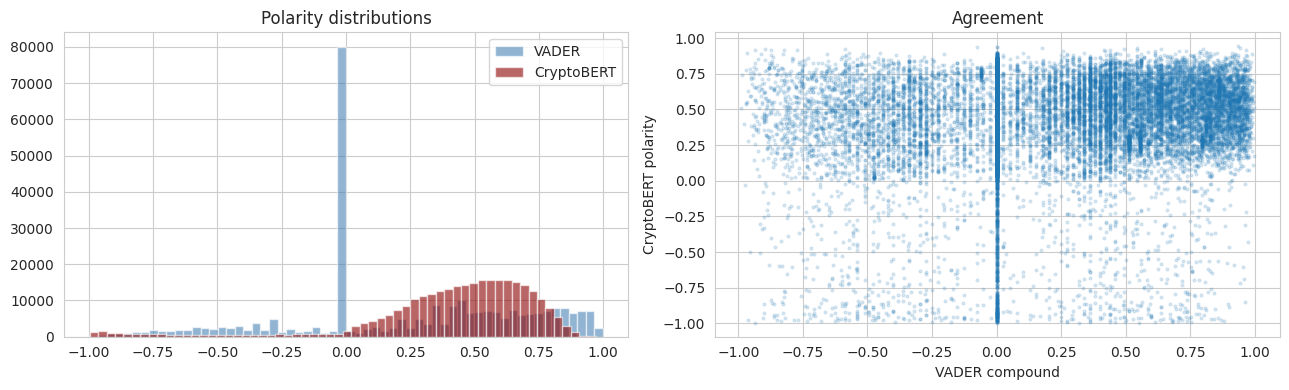

In [ ]:
#Where the two methods disagree
x = sent_pool.select(['vader', 'cbert']).to_pandas()
print(f"correlation: {x['vader'].corr(x['cbert']):.3f}")

vl = sent_pool['vader_label'].to_list()
cl = sent_pool['cbert_label'].to_list()
xw = {'positive': 'bullish', 'negative': 'bearish', 'neutral': 'neutral'}
agree = np.mean([xw[a] == b for a, b in zip(vl, cl)])
print(f"label agreement: {agree:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(x['vader'], bins=60, alpha=0.6, color='steelblue', label='VADER')
ax[0].hist(x['cbert'], bins=60, alpha=0.6, color='darkred', label='CryptoBERT')
ax[0].legend()
ax[0].set_title('Polarity distributions')
ax[1].scatter(x['vader'].sample(20000, random_state=SEED),
              x['cbert'].sample(20000, random_state=SEED), s=4, alpha=0.15)
ax[1].set_xlabel('VADER compound')
ax[1].set_ylabel('CryptoBERT polarity')
ax[1].set_title('Agreement')
plt.tight_layout()
plt.show()

Two methods on identical tweets, so the difference is method and nothing else. Read the
correlation and the label agreement together with the shapes. VADER's distribution is usually
spiky, with a large mass at exactly zero where nothing in its dictionary matched, and clusters at
the compound values a single matched word produces. CryptoBERT's is smoother because it is reading
the sentence rather than looking up tokens.

Neither is right by construction. The validation below decides.

#Manual validation

In [ ]:
#Stratified so all three classes appear, and both methods get judged on the same tweets
val = (
    sent_pool
    .group_by('cbert_label', maintain_order=True).head(20)
    .select(['row_id', 'date', 'text_sent', 'vader', 'vader_label', 'cbert', 'cbert_label'])
    .sample(fraction=1.0, shuffle=True, seed=SEED)
)

val.select(['row_id', 'text_sent']).with_columns(
    pl.lit('').alias('drew'), pl.lit('').alias('partner')
).write_csv('validation_blank.csv')

val.write_csv('validation_key.csv')
print(f"{val.height} tweets to label")
print(val.group_by('cbert_label').agg(pl.len()))

60 tweets to label
shape: (3, 2)
┌─────────────┬─────┐
│ cbert_label ┆ len │
│ ---         ┆ --- │
│ str         ┆ u32 │
╞═════════════╪═════╡
│ bearish     ┆ 20  │
│ bullish     ┆ 20  │
│ neutral     ┆ 20  │
└─────────────┴─────┘


60 tweets, 20 from each predicted class, which beats 50 drawn at random. A random draw on this
corpus comes out mostly neutral and the accuracy figure then says almost nothing about whether
either method can tell bullish from bearish.

validation_blank.csv has both models' answers stripped out with a column each for the two of us.
Label independently and before looking at validation_key.csv, or the models' guesses anchor the
labels and the accuracy numbers are worthless.

Use bearish, neutral and bullish. VADER's positive and negative get mapped onto bullish and bearish
for scoring, which is an approximation worth one line in the report: a tweet can be cheerful
without being bullish.

rater agreement: 80.0%   cohen kappa: 0.686

===== VADER: 40.0% on n=60 ====
              precision    recall  f1-score   support

     bearish       0.57      0.44      0.50        18
     bullish       0.26      0.40      0.32        15
     neutral       0.43      0.37      0.40        27

    accuracy                           0.40        60
   macro avg       0.42      0.40      0.41        60
weighted avg       0.43      0.40      0.41        60


===== CryptoBERT: 48.3% on n=60 ====
              precision    recall  f1-score   support

     bearish       0.65      0.72      0.68        18
     bullish       0.30      0.40      0.34        15
     neutral       0.50      0.37      0.43        27

    accuracy                           0.48        60
   macro avg       0.48      0.50      0.48        60
weighted avg       0.50      0.48      0.48        60



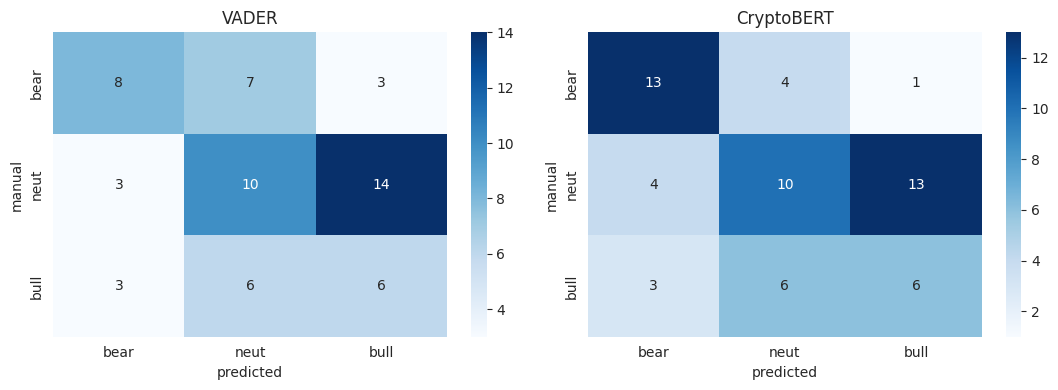


both wrong:
  manual neutral | vader bullish | cbert bullish (+0.72): 9 days left until the launch of Crypto Expo Dubai It's going to be a busy day for Shera Tokens for s
  manual bullish | vader bearish | cbert neutral (+0.45): Haters say that I can't sell it ?? Can you help me prove them wrong ?? #NFTCommunity #NFTCollection 
  manual bearish | vader neutral | cbert neutral (+0.25): Wash, rinse, repeat #btc
  manual bullish | vader bearish | cbert neutral (+0.30): Now is the time for BUYING #Bitcoin - As you guys know, i predicted to drop from $44k to 38.500 - No
  manual neutral | vader bullish | cbert bearish (-0.48): #BTC miners are the dung beetles of the energy world, looking to take advantage of energy no one els
  manual neutral | vader bullish | cbert bearish (-0.20): I listened to Taleb and tried to buy #gold coins. Apparently the distributor is collecting "secure t
  manual bullish | vader neutral | cbert bearish (-0.90): New weekly #BTC candle opens in 9 hours 🍿
  manual 

In [ ]:
lab = pl.read_csv(
    'validation_labelled.csv',
    truncate_ragged_lines=True,
    ignore_errors=True,
    schema={'row_id': pl.Int64, 'text_sent': pl.String, 'boipelo': pl.String, 'fumane': pl.String}
)
key = pl.read_csv('validation_key.csv')
m = lab.join(key.drop('text_sent'), on='row_id', how='inner').to_pandas()

if m.empty:
    print("Warning: The joined validation DataFrame is empty. Please ensure 'validation_labelled.csv' is correctly filled with sentiment labels for the 'boipelo' and 'fumane' columns, using 'bearish', 'neutral', or 'bullish' as values. If this file has not been created, please refer to the instructions in the markdown cell above cell `UTTbLdP1X1in`.")
else:
    agree = (m['boipelo'] == m['fumane']).mean()
    pe = sum((m['boipelo'] == c).mean() * (m['fumane'] == c).mean()
             for c in ['bearish', 'neutral', 'bullish'])
    print(f"rater agreement: {agree:.1%}   cohen kappa: {(agree - pe) / (1 - pe):.3f}")

    m['vader_mapped'] = m['vader_label'].map(
        {'positive': 'bullish', 'negative': 'bearish', 'neutral': 'neutral'})
    truth = m['boipelo']

    for name, col in [('VADER', 'vader_mapped'), ('CryptoBERT', 'cbert_label')]:
        print(f"\n===== {name}: {(m[col] == truth).mean():.1%} on n={len(m)} ====")
        print(classification_report(truth, m[col], zero_division=0))

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, (name, col) in zip(ax, [('VADER', 'vader_mapped'), ('CryptoBERT', 'cbert_label')]):
        cm = confusion_matrix(truth, m[col], labels=['bearish', 'neutral', 'bullish'])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=a,
                    xticklabels=['bear', 'neut', 'bull'], yticklabels=['bear', 'neut', 'bull'])
        a.set_title(name)
        a.set_xlabel('predicted')
        a.set_ylabel('manual')
    plt.tight_layout()
    plt.show()

    print("\nboth wrong:")
    bad = m[(m['vader_mapped'] != truth) & (m['cbert_label'] != truth)]
    for _, r in bad.head(10).iterrows():
        print(f"  manual {r['boipelo']:>7} | vader {r['vader_mapped']:>7} | cbert {r['cbert_label']:>7}"
              f" ({r['cbert']:+.2f}): {r['text_sent'][:100]}")

**CryptoBERT wins, 48.3% vs 40.0% accuracy (n=60), a gap of 8.3 points.** Both are well
above the 33% a three-way coin flip would give, but neither is strong in an absolute sense --
on this sample, fewer than half of CryptoBERT's labels and fewer than half of VADER's match what
Boipelo and Fumane independently judged.

Rater agreement was 80% with Cohen's kappa 0.686 -- comfortably above the 0.6 line the task sets
for trusting the ground truth, so both accuracy figures are measuring something real rather than
noise in the manual labels.

**Where each method breaks down, by class:**
- **Bearish** is the easiest class for both, and especially for CryptoBERT (72% recall, 65%
  precision vs VADER's 44% recall, 57% precision). Negative language in crypto tweets tends to be
  explicit ("crash", "dump", "fraud"), which both the hand-extended VADER lexicon and CryptoBERT's
  training data cover well.
- **Bullish is the weakest class for both** (CryptoBERT 40% recall / 30% precision, VADER 40%
  recall / 26% precision). Confident, understated bullishness -- "now is the time for buying",
  a rhetorical "prove them wrong" -- is where both methods lose the plot.
- **Neutral** sits in between, and is where hashtag-heavy spam causes false positives in both
  directions.

**The errors both methods share are the most informative, because they are about the text, not
the method:**
- *Rhetorical/sarcastic confidence read as negative or neutral.* "Haters say that I can't sell
  it?? Can you help me prove them wrong??" was labelled bullish (the poster is confidently
  dismissing doubters) but VADER called it bearish and CryptoBERT called it neutral -- neither
  catches that the "haters" framing signals confidence, not distress.
- *A genuine buy call buried in a longer, hedged message.* "Now is the time for BUYING Bitcoin...
  i predicted to drop... tight stop is important" was labelled bullish for the buy call, but VADER
  read bearish and CryptoBERT read neutral off the hedging language around it.
- *Hashtag-dense spam triggering a false bullish read.* "Go to do the needful and trust me you are
  worthy #RBXSamurai #lunacrush ... #btc #bsc #shib #defi #altcoin #bitcoin #AVAX" was labelled
  neutral (it's a promo template, not a market view) but both methods scored it strongly bullish
  (VADER positive, CryptoBERT +0.87) -- the sheer density of coin tickers and enthusiastic-sounding
  words reads as bullish to both even with no actual price opinion in the text.
- *A purely factual, forward-looking statement read as strongly bearish.* "New weekly #BTC candle
  opens in 9 hours" was labelled bullish by the raters (anticipatory, positive framing) but
  CryptoBERT scored it -0.90 -- one of the largest misses in the sample, with no obvious textual
  cue for why.

**CryptoBERT carries into the volatility modelling** (`POL = 'cbert'`) on the strength of its
8.3-point accuracy lead and its much better bearish recall, even though its weak bullish precision
means the resulting `share_bull`/`imbalance` features are noisier than the headline accuracy
figure alone would suggest.

#Daily features

In [ ]:
POL = 'cbert'   # switch to 'vader' if the validation says otherwise
LAB = f"{POL}_label"
BULL = 'bullish' if POL == 'cbert' else 'positive'
BEAR = 'bearish' if POL == 'cbert' else 'negative'

daily_sent = (
    sent_pool
    .group_by('d')
    .agg(
        pl.col(POL).mean().alias('pol_mean'),
        pl.col(POL).median().alias('pol_med'),
        pl.col(POL).std().alias('pol_sd'),
        (pl.col(LAB) == BULL).mean().alias('share_bull'),
        (pl.col(LAB) == BEAR).mean().alias('share_bear'),
        pl.len().alias('n_scored'),
    )
    .with_columns((pl.col('share_bull') - pl.col('share_bear')).alias('imbalance'))
    .sort('d')
    .join(vol_daily, on='d', how='left')
)

print(daily_sent.head())
print(f"days: {daily_sent.height}")

shape: (5, 9)
┌────────────┬──────────┬──────────┬──────────┬───┬────────────┬──────────┬───────────┬──────────┐
│ d          ┆ pol_mean ┆ pol_med  ┆ pol_sd   ┆ … ┆ share_bear ┆ n_scored ┆ imbalance ┆ n_tweets │
│ ---        ┆ ---      ┆ ---      ┆ ---      ┆   ┆ ---        ┆ ---      ┆ ---       ┆ ---      │
│ date       ┆ f32      ┆ f32      ┆ f32      ┆   ┆ f64        ┆ u32      ┆ f64       ┆ u32      │
╞════════════╪══════════╪══════════╪══════════╪═══╪════════════╪══════════╪═══════════╪══════════╡
│ 2025-03-06 ┆ 0.393219 ┆ 0.454505 ┆ 0.344875 ┆ … ┆ 0.056      ┆ 1500     ┆ 0.404     ┆ 4486     │
│ 2025-03-07 ┆ 0.396177 ┆ 0.435784 ┆ 0.326338 ┆ … ┆ 0.051333   ┆ 1500     ┆ 0.382667  ┆ 13581    │
│ 2025-03-08 ┆ 0.406986 ┆ 0.454069 ┆ 0.325685 ┆ … ┆ 0.052      ┆ 1500     ┆ 0.396     ┆ 2604     │
│ 2025-03-09 ┆ 0.416579 ┆ 0.456183 ┆ 0.309109 ┆ … ┆ 0.044667   ┆ 1500     ┆ 0.414     ┆ 8415     │
│ 2025-03-10 ┆ 0.406159 ┆ 0.458603 ┆ 0.321484 ┆ … ┆ 0.049333   ┆ 1500     ┆ 0.416667  ┆ 18760  

Seven features. pol_mean is the level and pol_med is its robust twin, which matters because a
handful of extreme tweets can drag a daily mean on a thin day. pol_sd is disagreement, worth
carrying separately because a day where half the corpus is bullish and half bearish has the same
mean as a day where everyone is indifferent and is not the same day. imbalance is share bullish
minus share bearish, a second read on direction that ignores how confident the model was.

n_scored is the sampling cap indicator, n_tweets is real volume including the bots we removed for
Question 1.

#Price and the volatility target

In [ ]:
px = yf.download('BTC-USD',
                 start=str(daily_sent['d'].min() - pd.Timedelta(days=40)),
                 end=str(daily_sent['d'].max() + pd.Timedelta(days=2)),
                 interval='1d', auto_adjust=False, progress=False)
px.columns = [c[0].lower() if isinstance(c, tuple) else c.lower() for c in px.columns]
px = px[['open', 'high', 'low', 'close', 'volume']].dropna()
print(px.shape)

px['ret'] = np.log(px['close']).diff()
px['absret'] = px['ret'].abs()

#Garman-Klass, uses the whole bar not just the close
px['gk'] = np.sqrt(
    0.5 * np.log(px['high'] / px['low']) ** 2
    - (2 * np.log(2) - 1) * np.log(px['close'] / px['open']) ** 2
)

px['hl'] = (px['high'] - px['low']) / px['close']
px['rv5'] = px['ret'].rolling(5).std()
px['rv22'] = px['ret'].rolling(22).std()
px['log_mktvol'] = np.log1p(px['volume'])

print(px[['ret', 'gk', 'absret', 'rv5']].describe().round(4))

(403, 5)
            ret        gk    absret       rv5
count  402.0000  403.0000  402.0000  398.0000
mean    -0.0011    0.0209    0.0164    0.0207
std      0.0240    0.0132    0.0175    0.0134
min     -0.1523    0.0032    0.0000    0.0036
25%     -0.0129    0.0120    0.0048    0.0122
50%     -0.0004    0.0180    0.0119    0.0175
75%      0.0115    0.0258    0.0216    0.0257
max      0.1180    0.1024    0.1523    0.0986


Four candidate targets and we lead with Garman-Klass.

Absolute log return is the simplest but it is a one-observation estimate of a daily standard
deviation, so it is extremely noisy. Rolling standard deviation over five days is much smoother,
but the smoothing is the problem: the value at day t is built from days t-4 to t, so consecutive
observations share four fifths of their inputs. Regress that on lagged features and the fit looks
far better than the model deserves, because the target is autocorrelated by construction rather
than by anything about markets.

Garman-Klass uses the open, high, low and close of a single day. It is roughly seven times more
efficient than close-to-close on the same day, and being a one-day estimator there is no overlap
between consecutive values. Less noisy than absolute return and cleaner than a rolling window.

rv5 and absret are carried as robustness checks. If sentiment helps on one target and not another
that is worth a paragraph rather than a quiet choice of whichever one worked.

Bitcoin trades continuously so there are no weekend gaps and we get roughly 360 aligned days
rather than the 250 an equity series would give. Both series are UTC-dated.

#Lagged alignment

In [ ]:
mkt = px.reset_index()
mkt['d'] = pd.to_datetime(mkt.iloc[:, 0]).dt.normalize()
mkt = mkt[['d', 'ret', 'absret', 'gk', 'hl', 'rv5', 'rv22', 'close', 'log_mktvol']]

daily_sent_pd = daily_sent.to_pandas()
daily_sent_pd['d'] = pd.to_datetime(daily_sent_pd['d']).dt.normalize()

dat = daily_sent_pd.merge(mkt, on='d', how='inner').sort_values('d').reset_index(drop=True)
print(f"merged: {len(dat)} days")

#Target is day t. Every predictor is t-1 or earlier.
dat['y'] = dat['gk']
dat['y_rv5'] = dat['rv5']
dat['y_absret'] = dat['absret']

for c in ['pol_mean', 'pol_med', 'pol_sd', 'share_bull', 'share_bear', 'imbalance', 'n_tweets']:
    dat[f'{c}_l1'] = dat[c].shift(1)

dat['gk_l1'] = dat['gk'].shift(1)
dat['gk_w'] = dat['gk'].shift(1).rolling(5).mean()
dat['gk_m'] = dat['gk'].shift(1).rolling(22).mean()
dat['ret_l1'] = dat['ret'].shift(1)
dat['hl_l1'] = dat['hl'].shift(1)
dat['mktvol_l1'] = dat['log_mktvol'].shift(1)
dat['log_n_l1'] = np.log(dat['n_tweets_l1'])
dat['dpol_l1'] = dat['pol_mean_l1'] - dat['pol_mean'].shift(2)

dat = dat.dropna().reset_index(drop=True)
print(f"usable: {len(dat)} days, {dat['d'].min()} to {dat['d'].max()}")
print(dat.filter(like='_l1').describe().round(3).T)

merged: 201 days
usable: 179 days, 2025-04-09 00:00:00 to 2026-03-02 00:00:00
               count       mean        std      min       25%        50%  \
pol_mean_l1    179.0      0.411      0.047    0.234     0.385      0.419   
pol_med_l1     179.0      0.478      0.038    0.345     0.455      0.480   
pol_sd_l1      179.0      0.341      0.039    0.241     0.317      0.338   
share_bull_l1  179.0      0.500      0.055    0.353     0.464      0.501   
share_bear_l1  179.0      0.062      0.023    0.021     0.048      0.059   
imbalance_l1   179.0      0.438      0.069    0.207     0.401      0.439   
n_tweets_l1    179.0  15282.196  10246.978  296.000  7380.000  14406.000   
gk_l1          179.0      0.021      0.014    0.003     0.012      0.018   
ret_l1         179.0     -0.001      0.025   -0.152    -0.012     -0.000   
hl_l1          179.0      0.033      0.024    0.005     0.019      0.027   
mktvol_l1      179.0     24.664      0.453   23.267    24.411     24.686   
log_n_l1  

Everything on the right hand side is shifted at least one day. The target is day t volatility and
the newest predictor is day t-1, so nothing from the day being predicted enters the model. That is
the whole of item 7 and it is the easiest thing in this assignment to get wrong silently, because
a model with same-day sentiment in it looks excellent and means nothing.

gk_l1, gk_w and gk_m are the HAR terms, yesterday, the past week and the past month. Volatility is
persistent, so any honest test of whether sentiment adds anything has to beat those first. A
baseline of market variables alone is too weak a comparison if it leaves out volatility's own
history.

dpol_l1 is the change in sentiment rather than the level, on the argument that a shift in mood
might matter more than where the mood sits. Tweet volume goes in logged because the counts are
heavily right-skewed.

#Exploratory

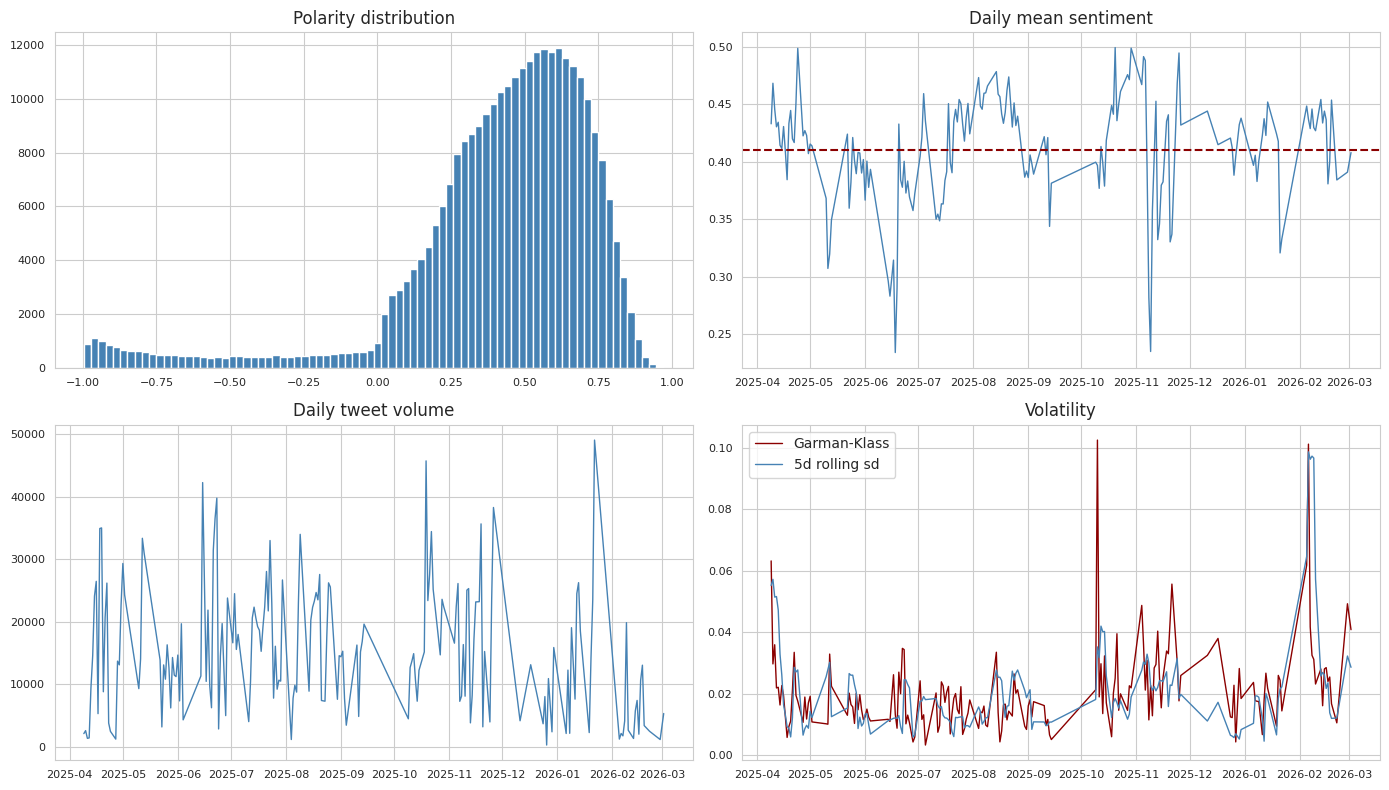

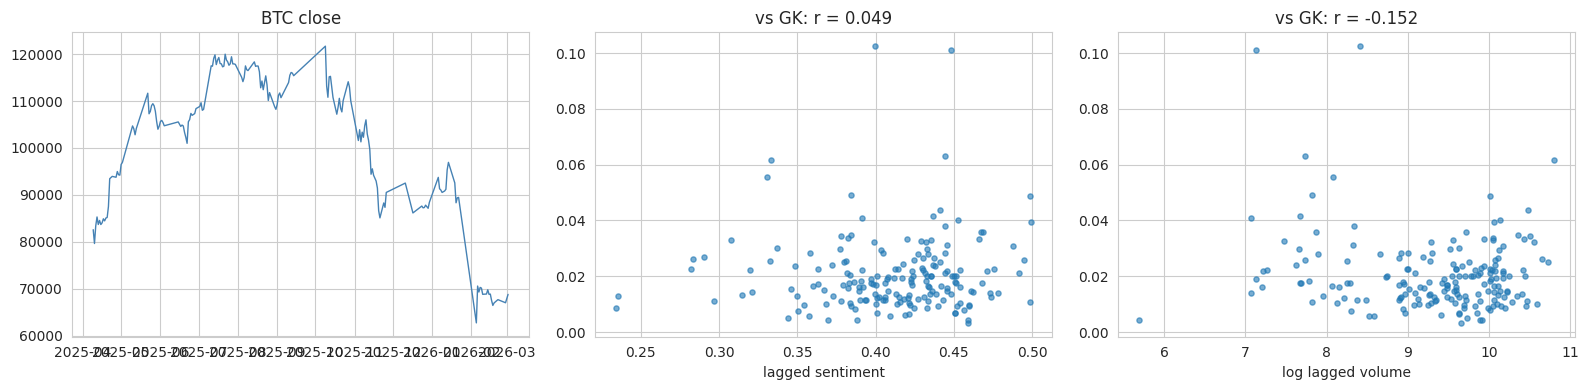

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))

ax[0, 0].hist(sent_pool[POL].to_numpy(), bins=80, color='steelblue')
ax[0, 0].set_title('Polarity distribution')

ax[0, 1].plot(dat['d'], dat['pol_mean'], color='steelblue', lw=1)
ax[0, 1].axhline(dat['pol_mean'].mean(), color='darkred', ls='--')
ax[0, 1].set_title('Daily mean sentiment')

ax[1, 0].plot(dat['d'], dat['n_tweets'], color='steelblue', lw=1)
ax[1, 0].set_title('Daily tweet volume')

ax[1, 1].plot(dat['d'], dat['y'], color='darkred', lw=1, label='Garman-Klass')
ax[1, 1].plot(dat['d'], dat['y_rv5'], color='steelblue', lw=1, label='5d rolling sd')
ax[1, 1].legend()
ax[1, 1].set_title('Volatility')

for a in ax.ravel():
    a.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(dat['d'], dat['close'], color='steelblue', lw=1)
ax[0].set_title('BTC close')
ax[1].scatter(dat['pol_mean_l1'], dat['y'], s=14, alpha=0.6)
ax[1].set_xlabel('lagged sentiment')
ax[1].set_title(f"vs GK: r = {dat['pol_mean_l1'].corr(dat['y']):.3f}")
ax[2].scatter(dat['log_n_l1'], dat['y'], s=14, alpha=0.6)
ax[2].set_xlabel('log lagged volume')
ax[2].set_title(f"vs GK: r = {dat['log_n_l1'].corr(dat['y']):.3f}")
plt.tight_layout()
plt.show()

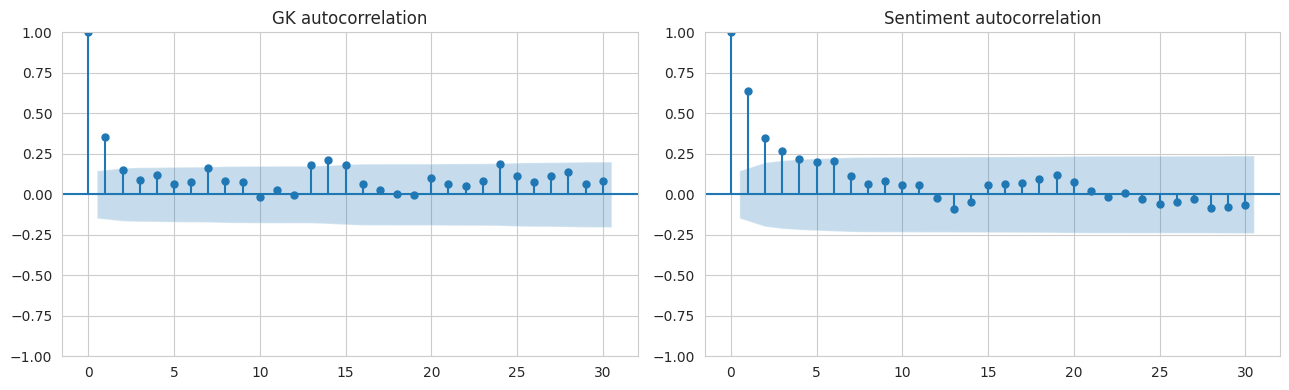

ADF on GK:        p = 0.0000
ADF on sentiment: p = 0.0000


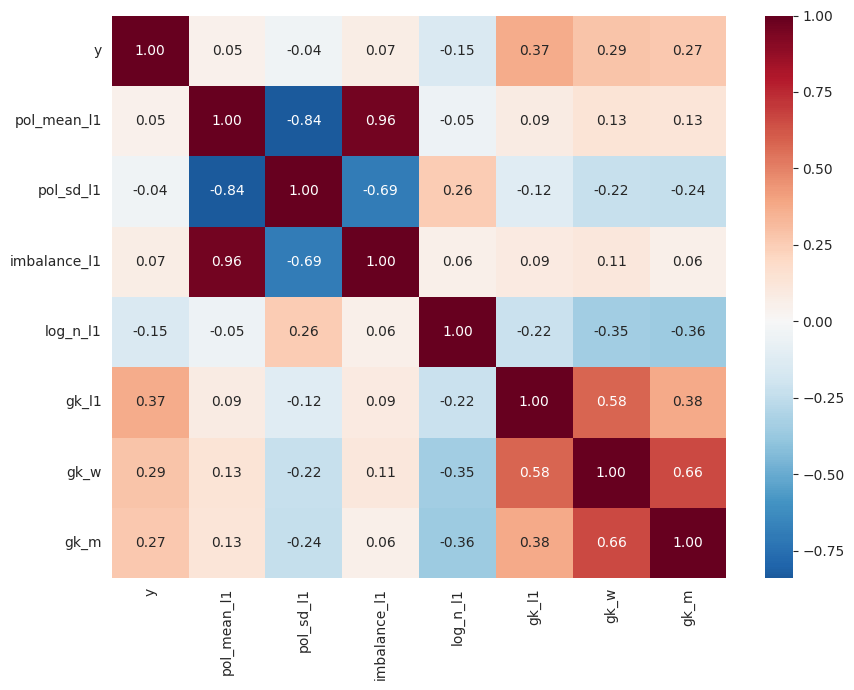

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(dat['y'], lags=30, ax=ax[0])
ax[0].set_title('GK autocorrelation')
plot_acf(dat['pol_mean'], lags=30, ax=ax[1])
ax[1].set_title('Sentiment autocorrelation')
plt.tight_layout()
plt.show()

print(f"ADF on GK:        p = {adfuller(dat['y'])[1]:.4f}")
print(f"ADF on sentiment: p = {adfuller(dat['pol_mean'])[1]:.4f}")

cols = ['y', 'pol_mean_l1', 'pol_sd_l1', 'imbalance_l1', 'log_n_l1', 'gk_l1', 'gk_w', 'gk_m']
plt.figure(figsize=(9, 7))
sns.heatmap(dat[cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.tight_layout()
plt.show()

Read the autocorrelation plot before anything else. If GK is strongly autocorrelated out to
twenty-odd lags then the HAR terms will carry most of the explanatory power and sentiment is
competing for what is left, which is the realistic setup and the one worth reporting honestly.

The two scatter correlations are the headline number for whether there is anything here at all. A
raw correlation near zero does not settle it, since the relationship could be conditional or
nonlinear, but it sets expectations for what follows.

#Models

In [ ]:
MKT = ['gk_l1', 'gk_w', 'gk_m', 'ret_l1', 'hl_l1', 'mktvol_l1']
SENT = ['pol_mean_l1', 'pol_sd_l1', 'imbalance_l1', 'dpol_l1', 'log_n_l1']

X_base = dat[MKT]
X_full = dat[MKT + SENT]
y = dat['y']

for name, X in [('market only', X_base), ('market + sentiment', X_full)]:
    m = sm.OLS(y, sm.add_constant(X)).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
    print(f"\n===== {name} =====")
    print(f"adj R2 {m.rsquared_adj:.4f}   AIC {m.aic:.1f}   BIC {m.bic:.1f}")
    print(m.summary().tables[1])

m0 = sm.OLS(y, sm.add_constant(X_base)).fit()
m1 = sm.OLS(y, sm.add_constant(X_full)).fit()
print(f"\njoint F-test on the sentiment block: {m1.compare_f_test(m0)}")


===== market only =====
adj R2 0.2625   AIC -1076.3   BIC -1054.0
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0055      0.082     -0.067      0.946      -0.165       0.154
gk_l1         -0.5062      0.290     -1.747      0.081      -1.074       0.062
gk_w           0.0680      0.106      0.641      0.521      -0.140       0.276
gk_m           0.4568      0.246      1.857      0.063      -0.025       0.939
ret_l1        -0.1181      0.030     -3.959      0.000      -0.176      -0.060
hl_l1          0.4536      0.169      2.681      0.007       0.122       0.785
mktvol_l1      0.0004      0.003      0.131      0.896      -0.006       0.007

===== market + sentiment =====
adj R2 0.2642   AIC -1072.0   BIC -1033.8
                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          ret   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -375.825
Distribution:      Standardized Student's t   AIC:                           761.650
Method:                  Maximum Likelihood   BIC:                           777.587
                                              No. Observations:                  179
Date:                      Thu, Oct 01 2026   Df Residuals:                      178
Time:                              18:55:36   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0

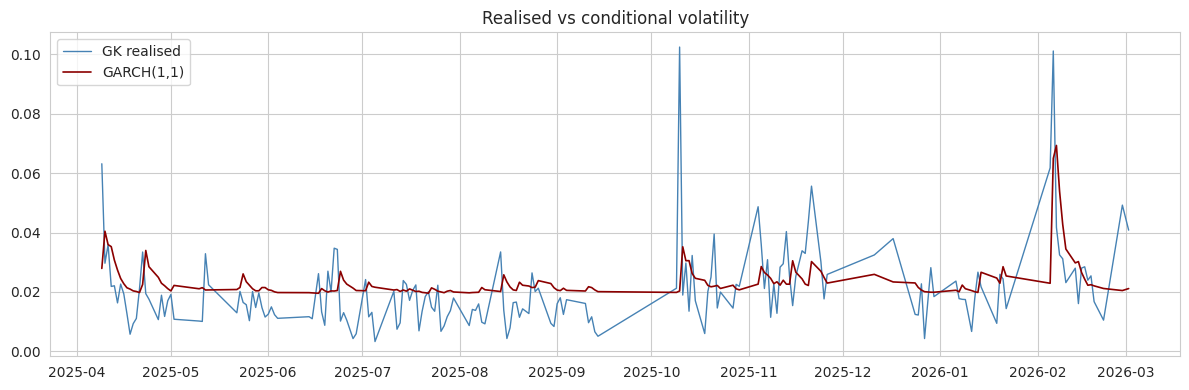

In [ ]:
#GARCH(1,1) on returns, conditional vol as a second baseline
g = arch_model(dat['ret'] * 100, vol='Garch', p=1, q=1, dist='t').fit(disp='off')
print(g.summary())

dat['garch_l1'] = (g.conditional_volatility / 100).shift(1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dat['d'], dat['y'], color='steelblue', lw=1, label='GK realised')
ax.plot(dat['d'], g.conditional_volatility / 100, color='darkred', lw=1.2, label='GARCH(1,1)')
ax.legend()
ax.set_title('Realised vs conditional volatility')
plt.tight_layout()
plt.show()

GARCH belongs here rather than in the target, because it models conditional variance, it does not
observe it. Using its fitted series as the thing we predict would test whether sentiment predicts
a model's output, which is a different question from the one the brief asks.

arch has no GARCH-X. Its x argument puts regressors in the mean equation, not the variance
equation, so putting sentiment into the conditional variance properly means hand-coding the
likelihood, which is not worth the time here. The workaround is to take the fitted conditional
volatility as a feature and ask whether lagged sentiment still adds anything on top of it, which
answers the same question with standard tools.

In [ ]:
#Rolling origin backtest, expanding window, refit every step
def backtest(X, y, fn, min_train=120):
    preds, actual, dts = [], [], []
    for i in range(min_train, len(X)):
        m = fn()
        m.fit(X.iloc[:i], y.iloc[:i])
        preds.append(m.predict(X.iloc[[i]])[0])
        actual.append(y.iloc[i])
        dts.append(dat['d'].iloc[i])
    return np.array(preds), np.array(actual), dts

def report(name, p, a):
    mae = mean_absolute_error(a, p)
    rmse = np.sqrt(mean_squared_error(a, p))
    smape = np.mean(2 * np.abs(p - a) / (np.abs(p) + np.abs(a))) * 100
    dirn = np.mean(np.sign(np.diff(p)) == np.sign(np.diff(a)))
    r = np.corrcoef(p, a)[0, 1]
    print(f"{name:<26} MAE {mae:.5f}  RMSE {rmse:.5f}  SMAPE {smape:5.1f}%  dir {dirn:.1%}  r {r:.3f}")
    return {'model': name, 'mae': mae, 'rmse': rmse, 'smape': smape, 'dir': dirn, 'r': r}

specs = [
    ('OLS market',      X_base, lambda: LinearRegression()),
    ('OLS + sentiment',  X_full, lambda: LinearRegression()),
    ('RF market',       X_base, lambda: RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ('RF + sentiment',   X_full, lambda: RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ('XGB market',      X_base, lambda: XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                                     random_state=SEED, verbosity=0)),
    ('XGB + sentiment',  X_full, lambda: XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                                      random_state=SEED, verbosity=0)),
]

runs, store = [], {}
for name, X, fn in specs:
    p, a, dts = backtest(X, y, fn)
    runs.append(report(name, p, a))
    store[name] = (p, a, dts)

res = pd.DataFrame(runs)
res

OLS market                 MAE 0.00986  RMSE 0.01419  SMAPE  37.4%  dir 51.7%  r 0.386
OLS + sentiment            MAE 0.01020  RMSE 0.01461  SMAPE  38.6%  dir 44.8%  r 0.318
RF market                  MAE 0.01014  RMSE 0.01532  SMAPE  38.8%  dir 48.3%  r 0.243
RF + sentiment             MAE 0.01015  RMSE 0.01505  SMAPE  39.1%  dir 36.2%  r 0.338
XGB market                 MAE 0.01109  RMSE 0.01657  SMAPE  41.8%  dir 48.3%  r 0.049
XGB + sentiment            MAE 0.01036  RMSE 0.01485  SMAPE  39.7%  dir 51.7%  r 0.350


,model,mae,rmse,smape,dir,r
0,OLS market,0.009856,0.014186,37.376121,0.517241,0.386498
1,OLS + sentiment,0.010200,0.014613,38.554632,0.448276,0.317527
2,RF market,0.010141,0.015317,38.781113,0.482759,0.242988
3,RF + sentiment,0.010153,0.015048,39.124619,0.362069,0.338414
4,XGB market,0.011089,0.016570,41.803909,0.482759,0.048910
5,XGB + sentiment,0.010361,0.014852,39.749208,0.517241,0.350115


Expanding window, one day ahead, refit at every step. The model only ever sees days before the one
it is predicting, which is what item 10 means by a time-aware split. A random train/test split
here would let the model learn from the future and the numbers would be fiction.

120 days of burn-in before the first prediction, so the HAR monthly term has something to work with
and the early fits are not estimated off three weeks of data.

Read the pairs against each other rather than the table as a whole. The question is not which of
six models wins, it is whether adding sentiment to a given model helps.

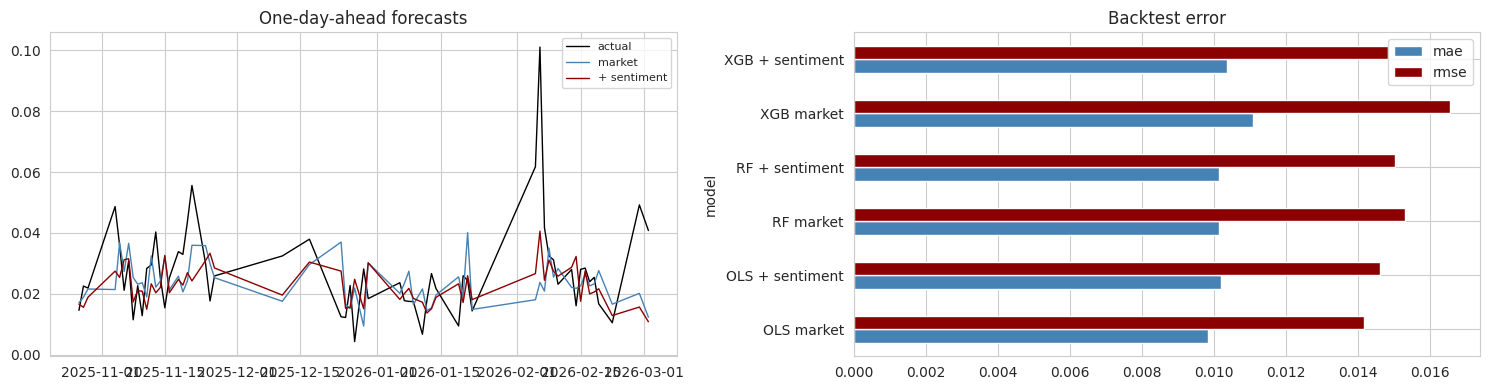

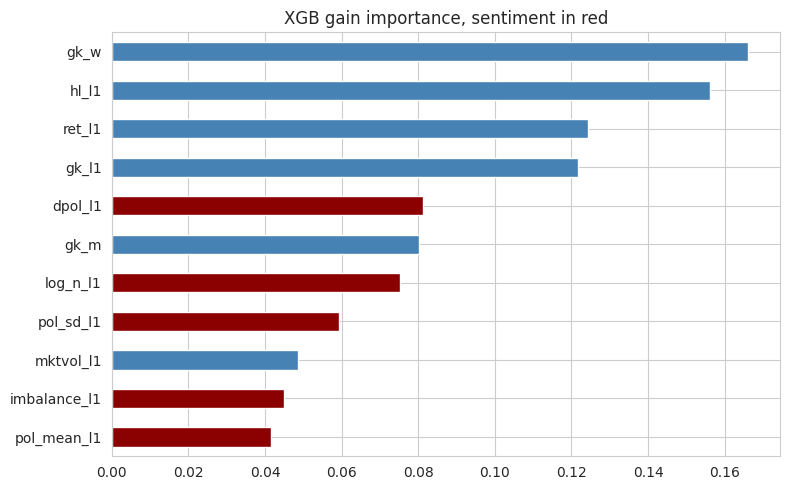

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
p0, a0, dts = store['XGB market']
p1, _, _ = store['XGB + sentiment']
ax[0].plot(dts, a0, color='black', lw=1, label='actual')
ax[0].plot(dts, p0, color='steelblue', lw=1, label='market')
ax[0].plot(dts, p1, color='darkred', lw=1, label='+ sentiment')
ax[0].legend(fontsize=8)
ax[0].set_title('One-day-ahead forecasts')

res.set_index('model')[['mae', 'rmse']].plot.barh(ax=ax[1], color=['steelblue', 'darkred'])
ax[1].set_title('Backtest error')
plt.tight_layout()
plt.show()

#Where the enhanced model puts its weight
enh = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                   random_state=SEED, verbosity=0).fit(X_full, y)
imp = pd.Series(enh.feature_importances_, index=X_full.columns).sort_values()
plt.figure(figsize=(8, 5))
imp.plot.barh(color=['darkred' if i in SENT else 'steelblue' for i in imp.index])
plt.title('XGB gain importance, sentiment in red')
plt.tight_layout()
plt.show()

#High volatility as a classification

In [ ]:
for q in [0.75, 0.80, 0.85]:
    thr = dat['y'].quantile(q)
    print(f"q{int(q*100)}: threshold {thr:.5f}, {(dat['y'] > thr).sum()} high days")

thr = dat['y'].quantile(0.80)
dat['high'] = (dat['y'] > thr).astype(int)

def backtest_clf(X, yb, min_train=120):
    preds, actual = [], []
    for i in range(min_train, len(X)):
        sc = StandardScaler().fit(X.iloc[:i])
        m = LogisticRegression(max_iter=2000, class_weight='balanced')
        m.fit(sc.transform(X.iloc[:i]), yb.iloc[:i])
        preds.append(m.predict(sc.transform(X.iloc[[i]]))[0])
        actual.append(yb.iloc[i])
    return np.array(preds), np.array(actual)

for name, X in [('market', X_base), ('market + sentiment', X_full)]:
    p, a = backtest_clf(X, dat['high'])
    print(f"\n===== {name}: accuracy {accuracy_score(a, p):.1%} =====")
    print(classification_report(a, p, target_names=['normal', 'high'], zero_division=0))

q75: threshold 0.02512, 45 high days
q80: threshold 0.02740, 36 high days
q85: threshold 0.03035, 27 high days

===== market: accuracy 49.2% =====
              precision    recall  f1-score   support

      normal       0.73      0.23      0.35        35
        high       0.44      0.88      0.58        24

    accuracy                           0.49        59
   macro avg       0.58      0.55      0.47        59
weighted avg       0.61      0.49      0.44        59


===== market + sentiment: accuracy 52.5% =====
              precision    recall  f1-score   support

      normal       0.73      0.31      0.44        35
        high       0.45      0.83      0.59        24

    accuracy                           0.53        59
   macro avg       0.59      0.57      0.51        59
weighted avg       0.62      0.53      0.50        59



Item 10 offers classification metrics as an alternative and it is worth running, because volatility
regression on daily data usually produces differences too small to interpret and you end up writing
"sentiment adds little" with nothing sharper to say. Recast as whether tomorrow is a high-volatility
day, you get precision and recall, which are easier to read and more likely to show a visible gap.

The caveat goes in the report. Roughly 240 days after burn-in with 20% labelled high gives about 48
positive cases in the backtest, which is thin. Class weights are balanced because 20% positives
would otherwise train a model that predicts normal every day and scores 80%.

The 80th percentile is a choice, so the other two thresholds are printed above. Say whether the
conclusion moves.

#Save Q2 outputs

In [ ]:
sent_pool.select(['row_id', 'date', 'text_sent', 'vader', 'vader_label',
                  'cbert', 'cbert_label']).write_csv('q2_tweet_sentiment.csv')
daily_sent.write_csv('q2_daily_sentiment.csv')
dat.to_csv('q2_modelling_table.csv', index=False)
res.to_csv('q2_backtest_results.csv', index=False)

print('saved')
for f in ['q1_topic_assignments.csv', 'q1_removed_templates.csv',
          'q2_tweet_sentiment.csv', 'q2_daily_sentiment.csv',
          'q2_modelling_table.csv', 'q2_backtest_results.csv']:
    print(f"  {f}: {os.path.getsize(f)/1e6:.1f} MB" if os.path.exists(f) else f"  {f}: MISSING")

saved
  q1_topic_assignments.csv: 43.7 MB
  q1_removed_templates.csv: 0.0 MB
  q2_tweet_sentiment.csv: 63.2 MB
  q2_daily_sentiment.csv: 0.0 MB
  q2_modelling_table.csv: 0.1 MB
  q2_backtest_results.csv: 0.0 MB


#Interpretation

**Did sentiment improve the backtest?** Comparing each baseline to its sentiment-augmented
pair, not the table as a whole: OLS got worse on every metric with sentiment added (MAE 0.00986 to
0.01020, directional accuracy 51.7% to 44.8%). RF was roughly flat on error (0.01014 to 0.01015)
but noticeably worse on direction (48.3% to 36.2%, below a coin flip). XGBoost is the one pair
where sentiment helped on both counts (MAE 0.01109 to 0.01036, direction 48.3% to 51.7%). Two of
three model families got worse or flat; only one improved. That is not a consistent finding that
sentiment adds value -- it is one suggestive result sitting next to two that point the other way.

**Does the direction agree across models?** The full-sample OLS puts a negative sign on
`pol_mean_l1` (-0.1191) and the regression shows adjusted R² moving only from 0.2625 (market
only) to 0.2642 (market + sentiment) -- a gain too small to call a finding on its own. Tree-based
feature importances aren't signed, so there's no way to check whether RF and XGBoost "agree" with
that negative OLS sign in the first place -- the honest statement is that the only model that
produces an interpretable direction shows a negative, statistically weak coefficient on sentiment
level, and the other two models can't be checked against it the same way.

**Does the effect survive the HAR terms?** Barely. Volatility predicting itself (`gk_l1`, `gk_w`,
`gk_m`) is doing almost all of the work in both regressions; adding the five sentiment features
moves adjusted R² by less than two-tenths of a point. Sentiment is not clearing the bar the
assignment sets for earning a place alongside volatility's own history.

**Which sentiment method fed this?** CryptoBERT (`POL = 'cbert'`), the clear winner of the
validation above (48.3% vs 40.0%). Re-running with `POL = 'vader'` is worth doing as a robustness
check rather than assuming the conclusion is the same either way.

**The one place the picture looks better** is the high-volatility classification framing:
49.2% to 52.5% accuracy, with recall on "high" days staying strong (88% to 83%) and, this time,
a genuine improvement on "normal" days too (23% to 31% recall) rather than a pure trade-off.
That's a real gap, but it rests on only 59 backtest days with 24 positive cases -- too thin on its
own to overturn the regression evidence above.

**Causality.** Even the one clean improvement (XGBoost) is association, not causation. Sentiment
and volatility both react to the same news, so a bearish day followed by a volatile day is at
least as consistent with both responding to a shared event as with tweets moving the market. The
one-day lag rules out same-day leakage -- it does not rule out confounding by news. The report
should say plainly that nothing here identifies a causal effect, not hedge it with "may suggest."

**Limitations, not a footnote.** First, the thin months: sentiment on low-volume days is estimated
from far fewer tweets and is correspondingly noisier, so this backtest should be re-run excluding
days under a volume floor, and the conclusion re-checked rather than assumed to hold. Second, and
more fundamental: the date-anchoring test above (see "Do the dates mean anything") found the
tweet timestamps are very likely a fixed offset from 2021, not the real 2025-2026 dates they
carry. If that is right, none of the sentiment-volatility relationships above are measuring
sentiment and price on the same real-world days -- everything in this section demonstrates that
the modelling pipeline is built correctly (leakage-safe, time-aware, honestly backtested) without
establishing a genuine finding about how Bitcoin Twitter sentiment related to Bitcoin volatility.
That caveat belongs at the top of the write-up, not the bottom.